Name - Sunidhi Priya

Reg No- 23BDS0112

Slot - L23+ L24

EDA Course Project

In [ ]:
# Assignment 1

import pandas as pd
import numpy as np

# Create dataframes
dataframe1 = pd.DataFrame({
    "ProductID": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    "NameofProd": ["Phone", "TV", "Mobile", "Headset", "Phone",
                   "TV", "Mobile", "Headset", "Phone", "TV"],
    "Price": [200, 300, 100, 400, 5, 200, 600, 200, 600, 300]
})

dataframe2 = pd.DataFrame({
    "ProductID": [1, 2, 13, 4, 5, 16, 7, 18, 19, 10],
    "Company_Location": ["Delhi", "Goa", "Patna", "Delhi", "Goa",
                         "Patna", "Delhi", "Goa", "Patna", "Bangalore"]
})

dataframe3 = pd.DataFrame({
    "ProductID": [11, 12, 13, 14, 15, 16, 17, 18, 19, 20],
    "NameofProd": ["Phone", "TV", "Mobile", "Headset", "Phone",
                   "TV", "Mobile", "Headset", "Phone", "TV"],
    "Price": [200, 300, 100, 400, 5, 200, 600, 200, 600, 300]
})

print(dataframe1)
print(dataframe2)
print(dataframe3)

# 1. Append the records of dataframe1 and dataframe3 (new rows)
append_df = pd.concat([dataframe1, dataframe3], ignore_index=True)
print(append_df)

# 2. Concatenate the data frames wherever applicable (new column)
concat_df = pd.concat(
    [dataframe1, dataframe2[["Company_Location"]]], axis=1
)
print(concat_df)

# 3. Merge dataframe1 and dataframe2 using ProductID
merge_df = pd.merge(dataframe1, dataframe2, on="ProductID")
print(merge_df)

# 4. Perform Inner, Left, Right and Full Outer Joins
inner_join_df = pd.merge(dataframe1, dataframe2,
                         on="ProductID", how="inner")
left_join_df = pd.merge(dataframe1, dataframe2,
                        on="ProductID", how="left")
right_join_df = pd.merge(dataframe1, dataframe2,
                         on="ProductID", how="right")
full_join_df = pd.merge(dataframe1, dataframe2,
                        on="ProductID", how="outer")

print(inner_join_df)
print(left_join_df)
print(right_join_df)
print(full_join_df)

# Numeric vector using first name as object name
Sunidhi = np.array([112, 23, 45, 67, 43, 67, 89, 654, 678, 643],
                   dtype=float)
print(Sunidhi)

# 1. Normalize data to [-3, +3], [-1, +1] and [0, 1]
minval = Sunidhi.min()
maxval = Sunidhi.max()

normal3 = ((Sunidhi - minval) / (maxval - minval)) * 6 - 3
normal1 = ((Sunidhi - minval) / (maxval - minval)) * 2 - 1
normal_minmax = (Sunidhi - minval) / (maxval - minval)

print("Normalized [-3, 3]:", normal3)
print("Normalized [-1, 1]:", normal1)
print("Min-Max [0, 1]:", normal_minmax)

# 2. Transform the data into Z-score format
z_score = (Sunidhi - Sunidhi.mean()) / Sunidhi.std(ddof=1)
print("Z-score:", z_score)

# 3. Transform the data using Decimal Scaling Normalization
j = len(str(int(np.max(np.abs(Sunidhi)))))
decimal_scaling = Sunidhi / (10 ** j)
print("Decimal scaling:", decimal_scaling)

   ProductID NameofProd  Price
0          1      Phone    200
1          2         TV    300
2          3     Mobile    100
3          4    Headset    400
4          5      Phone      5
5          6         TV    200
6          7     Mobile    600
7          8    Headset    200
8          9      Phone    600
9         10         TV    300
   ProductID Company_Location
0          1            Delhi
1          2              Goa
2         13            Patna
3          4            Delhi
4          5              Goa
5         16            Patna
6          7            Delhi
7         18              Goa
8         19            Patna
9         10        Bangalore
   ProductID NameofProd  Price
0         11      Phone    200
1         12         TV    300
2         13     Mobile    100
3         14    Headset    400
4         15      Phone      5
5         16         TV    200
6         17     Mobile    600
7         18    Headset    200
8         19      Phone    600
9         20       

In [ ]:
# Assignment 2

import pandas as pd
import numpy as np

# 1. Import dataset
url = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/house%20price.csv"
data = pd.read_csv(url)

# 2. Display first 10 records
print(data.head(10))

# 3. Display last 10 records
print(data.tail(10))

# 4. Total number of rows and columns
print("Dimensions:", data.shape)
print("Rows:", len(data))
print("Columns:", len(data.columns))

# 5. Display column names
print(data.columns.tolist())

# 6. Display structure (data types)
print(data.info())

# 7. Summary statistics
print(data.describe(include="all"))

# 8. Missing values in each column
print(data.isna().sum())

# 9. Total number of missing values
print("Total missing values:", data.isna().sum().sum())

# 10. Missing values in each column again
print(data.isna().sum())

# 11. Rows containing at least one missing value
print(data[data.isna().any(axis=1)])

# 12. Remove rows with missing values
clean_data = data.dropna()
print(clean_data.head())

# Find numerical columns
num_cols = data.select_dtypes(include=np.number).columns.tolist()
print(num_cols)

# 13. Replace missing values in first numerical column using mean
data_mean = data.copy()

if len(num_cols) >= 1:
    col1 = num_cols[0]
    data_mean[col1] = data_mean[col1].fillna(data_mean[col1].mean())

# 14. Replace missing values in second numerical column using median
if len(num_cols) >= 2:
    col2 = num_cols[1]
    data_mean[col2] = data_mean[col2].fillna(data_mean[col2].median())

print(data_mean.isna().sum())

# Find categorical columns
cat_cols = data.select_dtypes(
    include=["object", "category"]
).columns.tolist()
print(cat_cols)

# Function to calculate mode
def get_mode(series):
    modes = series.mode(dropna=True)
    return modes.iloc[0] if not modes.empty else "Unknown"

# 15. Replace missing values in first categorical column using mode
data_mode = data.copy()

if len(cat_cols) >= 1:
    col3 = cat_cols[0]
    data_mode[col3] = data_mode[col3].fillna(get_mode(data_mode[col3]))

print(data_mode.isna().sum())

# 16. Forward Fill
data_ffill = data.ffill()
print(data_ffill.head(10))

# 17. Backward Fill
data_bfill = data.bfill()
print(data_bfill.head(10))

# 18. Replace remaining missing values with 0 or "Unknown"
data_final = data_bfill.copy()

for col in data_final.columns:
    if pd.api.types.is_numeric_dtype(data_final[col]):
        data_final[col] = data_final[col].fillna(0)
    else:
        data_final[col] = data_final[col].fillna("Unknown")

print("Missing values:", data_final.isna().sum().sum())

# 19. Remove duplicate records
data_unique = data_final.drop_duplicates().copy()
print("Duplicate rows remaining:", data_unique.duplicated().sum())

# 20. Convert character variables to factors (category in Python)
for col in data_unique.select_dtypes(include="object").columns:
    data_unique[col] = data_unique[col].astype("category")

print(data_unique.dtypes)

# 21. Rename first column
data_unique = data_unique.rename(
    columns={data_unique.columns[0]: "New_Column_Name"}
)
print(data_unique.columns.tolist())

# 22. Create a derived column by doubling the first numeric column
num_cols2 = data_unique.select_dtypes(include=np.number).columns.tolist()

if len(num_cols2) >= 1:
    data_unique["Derived_Value"] = data_unique[num_cols2[0]] * 2

print(data_unique.head())

# 23. Summary statistics
print(data_unique.describe(include="all"))

# 24. Minimum and Maximum values
if num_cols2:
    print("Minimum:", data_unique[num_cols2[0]].min())
    print("Maximum:", data_unique[num_cols2[0]].max())

# 25. Range
if num_cols2:
    print("Range:", data_unique[num_cols2[0]].min(),
          data_unique[num_cols2[0]].max())

# 26. Variance
if num_cols2:
    print("Variance:", data_unique[num_cols2[0]].var())

# 27. Standard Deviation
if num_cols2:
    print("Standard deviation:", data_unique[num_cols2[0]].std())

# 28. Interquartile Range (IQR)
if num_cols2:
    col = data_unique[num_cols2[0]]
    print("IQR:", col.quantile(0.75) - col.quantile(0.25))

            date      price  bedrooms  bathrooms  sqft_living  sqft_lot  \
0  02/05/14 0:00   313000.0         3       1.50         1340      7912   
1  02/05/14 0:00  2384000.0         5       2.50         3650      9050   
2  02/05/14 0:00   342000.0         3       2.00         1930     11947   
3  02/05/14 0:00   420000.0         3       2.25         2000      8030   
4  02/05/14 0:00   550000.0         4       2.50         1940     10500   
5  02/05/14 0:00   490000.0         2       1.00          880      6380   
6  02/05/14 0:00   335000.0         2       2.00         1350      2560   
7  02/05/14 0:00   482000.0         4       2.50         2710     35868   
8  02/05/14 0:00   452500.0         3       2.50         2430     88426   
9  02/05/14 0:00   640000.0         4       2.00         1520      6200   

   floors waterfront  view  condition  sqft_above  sqft_basement  yr_built  \
0     1.5          0   0.0          3        1340              0      1955   
1     2.0         

            date      price  bedrooms  bathrooms  sqft_living  sqft_lot  \
0  02/05/14 0:00   313000.0         3       1.50         1340      7912   
1  02/05/14 0:00  2384000.0         5       2.50         3650      9050   
2  02/05/14 0:00   342000.0         3       2.00         1930     11947   
3  02/05/14 0:00   420000.0         3       2.25         2000      8030   
4  02/05/14 0:00   550000.0         4       2.50         1940     10500   
5  02/05/14 0:00   490000.0         2       1.00          880      6380   

   floors waterfront  view  condition  sqft_above  sqft_basement  yr_built  \
0     1.5          0   0.0          3        1340              0      1955   
1     2.0          0   4.0          5        3370            280      1921   
2     1.0          0   0.0          4        1930              0      1966   
3     1.0          0   0.0          4        1000           1000      1963   
4     1.0          0   0.0          4        1140            800      1976   
5     

/tmp/ipykernel_2895/3232026879.py:67: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["date"] = pd.to_datetime(df["date"], errors="coerce")


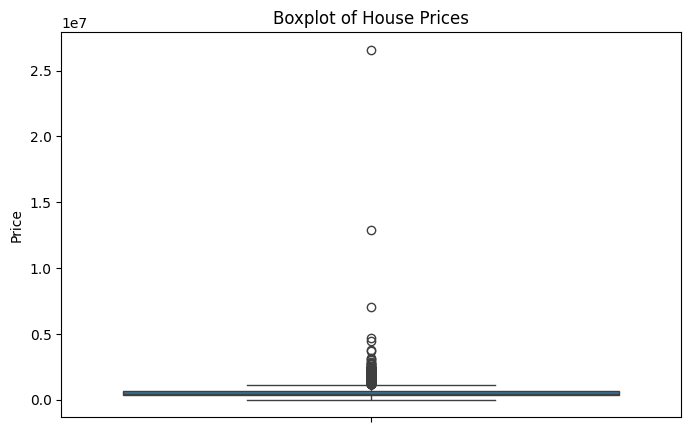

Q1 = 322875.0
Q3 = 654962.5
IQR = 332087.5
Lower Bound = -175256.25
Upper Bound = 1153093.75
Number of outliers = 240
           date         price  bedrooms  bathrooms  sqft_living  sqft_lot  \
1    2014-02-05  2.384000e+06         5       2.50         3650      9050   
11   2014-02-05  1.400000e+06         4       2.50         2920      4000   
14   2014-02-05  1.200000e+06         5       2.75         2910      9480   
99   2014-05-05  1.395000e+06         5       3.50         4010      8510   
122  2014-05-05  2.280000e+06         7       8.00        13540    307752   
...         ...           ...       ...        ...          ...       ...   
4348 2014-05-05  2.199900e+06         4       1.50         1120      5427   
4350 2014-03-07  2.659000e+07         3       2.00         1180      7793   
4465 2014-05-06  2.560498e+06         3       2.50         1710      1664   
4467 2014-06-06  1.337044e+06         4       3.50         4280      9583   
4572 2014-02-07  1.288333e+06      

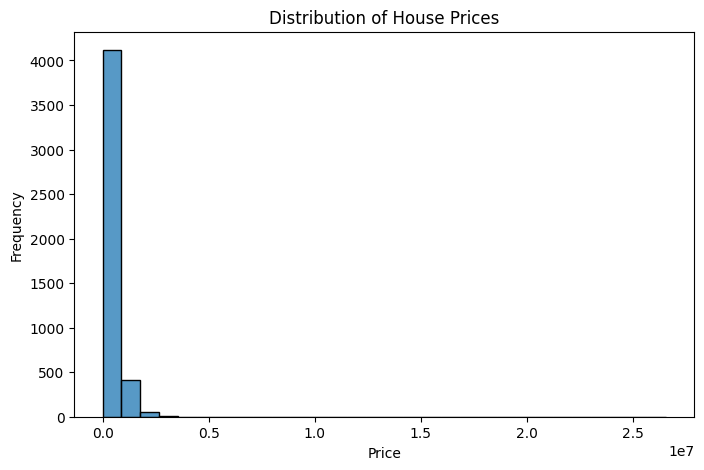

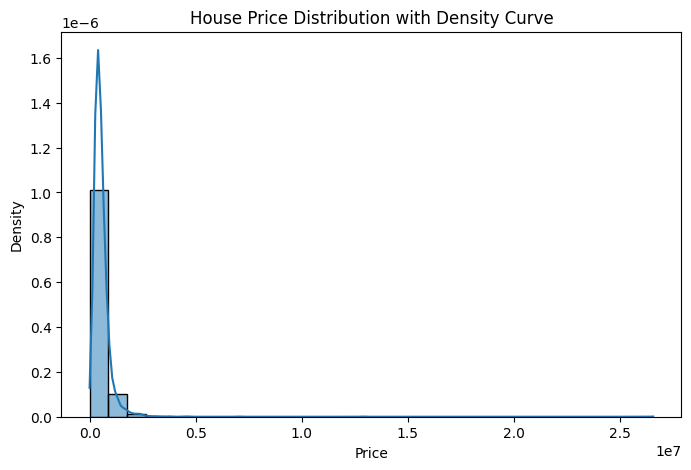

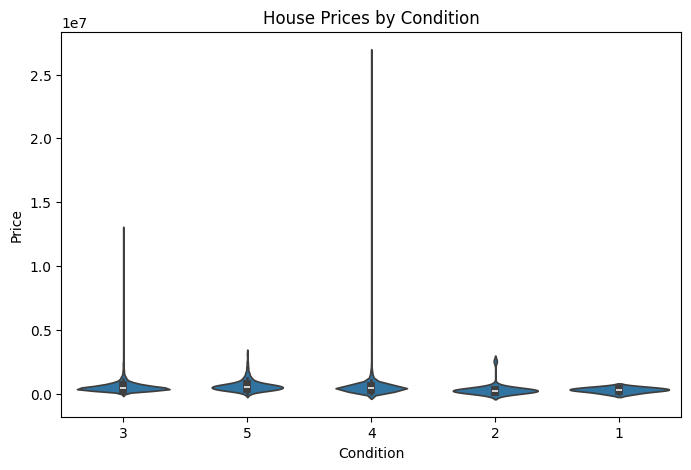

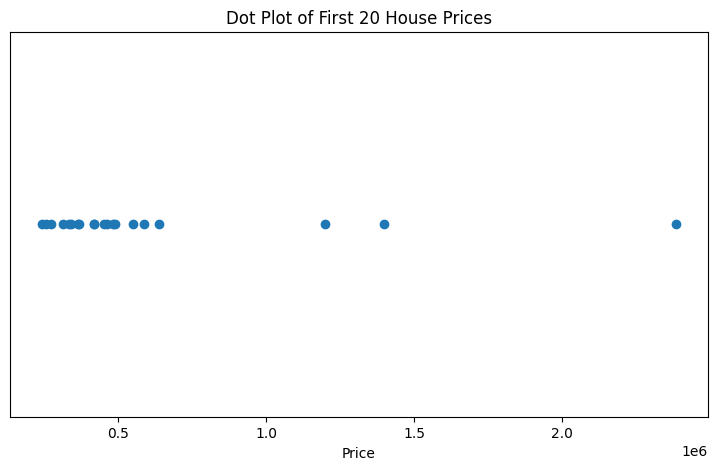

condition
1       6
2      32
3    2875
4    1252
5     435
Name: count, dtype: int64
   Condition  Frequency  Proportion  Percentage
0          1          6    0.001304    0.130435
1          2         32    0.006957    0.695652
2          3       2875    0.625000   62.500000
3          4       1252    0.272174   27.217391
4          5        435    0.094565    9.456522


In [ ]:
# Assignment 3

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Import a dataset into Python
url = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/house%20price.csv"
df = pd.read_csv(url)
df_original = df.copy()

# 2. Display the first and last six records
print(df.head(6))
print(df.tail(6))

# 3. Identify the total number of missing values
print(df.isna().sum().sum())

# 4. Display all records containing at least one missing value
print(df[df.isna().any(axis=1)])

# 5. Remove columns having more than 70% missing values
missing_percentage = df.isna().mean() * 100
print(missing_percentage)
df = df.loc[:, missing_percentage <= 70]
print(df.columns.tolist())

# 6. Replace missing numerical values with the mean
df_mean = df.copy()
num_cols = df_mean.select_dtypes(include=np.number).columns

for col in num_cols:
    df_mean[col] = df_mean[col].fillna(df_mean[col].mean())

print(df_mean.isna().sum())

# 7. Replace missing numerical values with the median
df_median = df.copy()

for col in df_median.select_dtypes(include=np.number).columns:
    df_median[col] = df_median[col].fillna(df_median[col].median())

print(df_median.isna().sum())

# 8. Replace missing categorical values with the mode
df_mode = df.copy()

for col in df_mode.select_dtypes(include=["object", "category"]).columns:
    modes = df_mode[col].mode(dropna=True)
    if not modes.empty:
        df_mode[col] = df_mode[col].fillna(modes.iloc[0])

print(df_mode.isna().sum())

# 9. Identify duplicate rows
print("Duplicate rows:", df.duplicated().sum())
print(df[df.duplicated()])

# 10. Remove duplicate rows
df = df.drop_duplicates()
print("Duplicates after removal:", df.duplicated().sum())

# 11. Identify columns stored with incorrect data types
if "date" in df.columns:
    print("Before:", df["date"].dtype)
    df["date"] = pd.to_datetime(df["date"], errors="coerce")
    print("After:", df["date"].dtype)

# 12. Convert character variables into categorical variables
for col in ["waterfront", "street", "city", "statezip", "country"]:
    if col in df.columns:
        df[col] = df[col].astype("category")

print(df.dtypes)

# 13. Convert text values into lowercase / uppercase
if "city" in df.columns:
    df["city"] = df["city"].astype(str).str.lower()
    df["city"] = df["city"].str.upper()

# 14. Detect outliers using boxplots
plt.figure(figsize=(8, 5))
sns.boxplot(y=df["price"])
plt.title("Boxplot of House Prices")
plt.ylabel("Price")
plt.show()

# 15. Identify outliers using the Interquartile Range (IQR)
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)
IQR_value = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR_value
upper_bound = Q3 + 1.5 * IQR_value

print("Q1 =", Q1)
print("Q3 =", Q3)
print("IQR =", IQR_value)
print("Lower Bound =", lower_bound)
print("Upper Bound =", upper_bound)

outliers = df[
    (df["price"] < lower_bound) |
    (df["price"] > upper_bound)
]

print("Number of outliers =", len(outliers))
print(outliers)

# 16. Remove extreme outliers from the dataset
df_no_outliers = df[
    (df["price"] >= lower_bound) &
    (df["price"] <= upper_bound)
]

print("Original number of rows =", len(df))
print("Rows after removing outliers =", len(df_no_outliers))

# 17. Create a histogram for a numerical variable
plt.figure(figsize=(8, 5))
sns.histplot(df["price"].dropna(), bins=30)
plt.title("Distribution of House Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()

# 18. Add a density curve to the histogram
plt.figure(figsize=(8, 5))
sns.histplot(df["price"].dropna(), bins=30, stat="density", kde=True)
plt.title("House Price Distribution with Density Curve")
plt.xlabel("Price")
plt.ylabel("Density")
plt.show()

# 19. Create a violin plot
plt.figure(figsize=(8, 5))
sns.violinplot(data=df, x=df["condition"].astype(str), y="price")
plt.title("House Prices by Condition")
plt.xlabel("Condition")
plt.ylabel("Price")
plt.show()

# 20. Create a dot plot for the first 20 house prices
small_data = df.head(20)

plt.figure(figsize=(9, 5))
plt.scatter(small_data["price"], np.zeros(len(small_data)))
plt.yticks([])
plt.title("Dot Plot of First 20 House Prices")
plt.xlabel("Price")
plt.show()

# 21. Create a frequency table for a categorical variable
frequency_table = df["condition"].value_counts(
    dropna=False
).sort_index()

print(frequency_table)

# 22. Calculate proportion and percentage of each category
proportion = frequency_table / frequency_table.sum()
percentage = proportion * 100

result = pd.DataFrame({
    "Condition": frequency_table.index,
    "Frequency": frequency_table.values,
    "Proportion": proportion.values,
    "Percentage": percentage.values
})

print(result)

            date      price  bedrooms  bathrooms  sqft_living  sqft_lot  \
0  02/05/14 0:00   313000.0         3       1.50         1340      7912   
1  02/05/14 0:00  2384000.0         5       2.50         3650      9050   
2  02/05/14 0:00   342000.0         3       2.00         1930     11947   
3  02/05/14 0:00   420000.0         3       2.25         2000      8030   
4  02/05/14 0:00   550000.0         4       2.50         1940     10500   

   floors waterfront  view  condition  sqft_above  sqft_basement  yr_built  \
0     1.5          0   0.0          3        1340              0      1955   
1     2.0          0   4.0          5        3370            280      1921   
2     1.0          0   0.0          4        1930              0      1966   
3     1.0          0   0.0          4        1000           1000      1963   
4     1.0          0   0.0          4        1140            800      1976   

   yr_renovated                    street       city  statezip country  
0      

/tmp/ipykernel_2895/3803990617.py:22: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  house["date"] = pd.to_datetime(house["date"], errors="coerce")


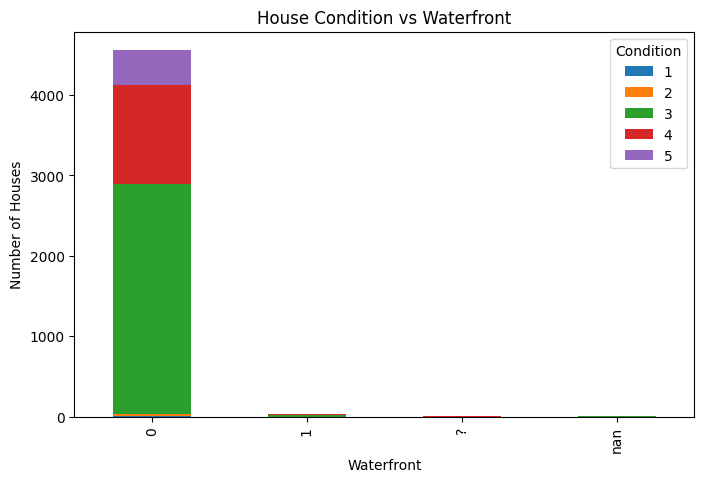

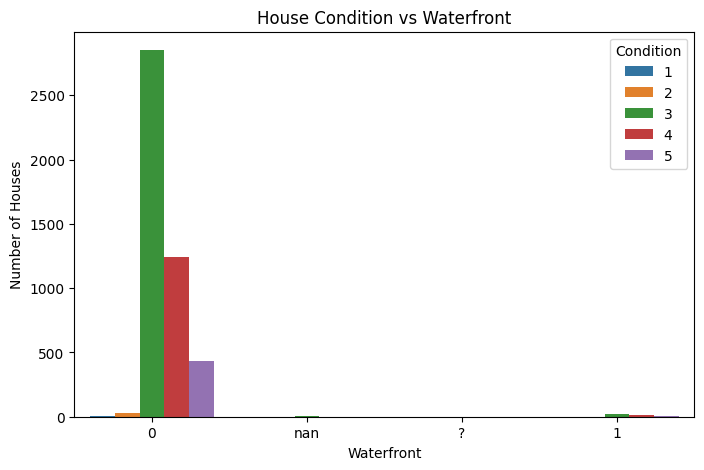

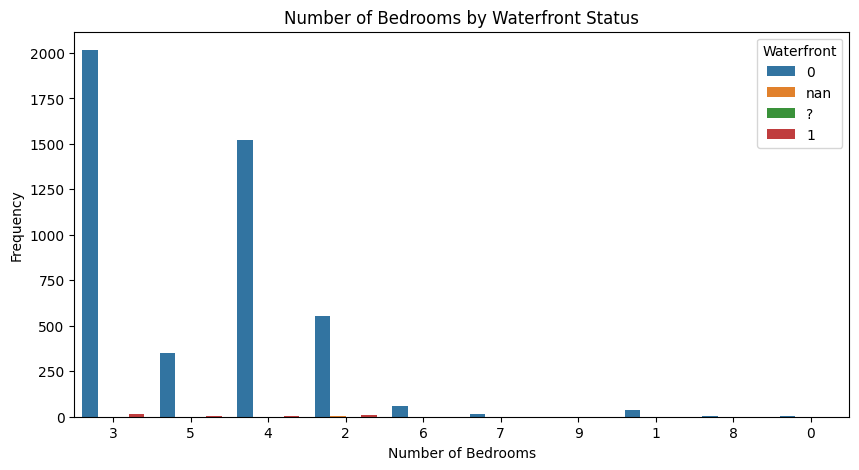

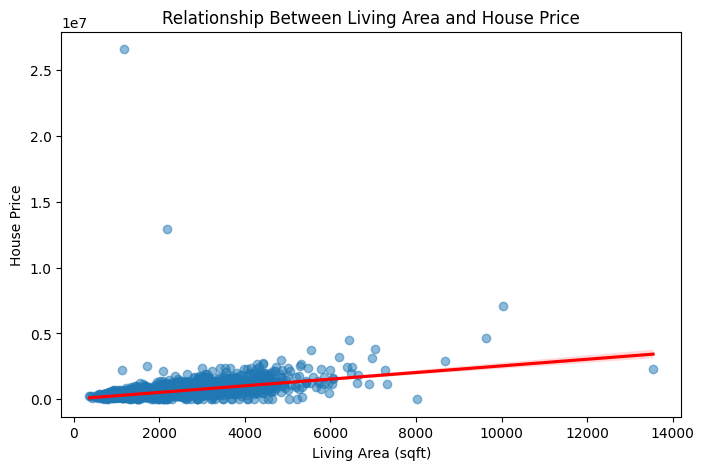

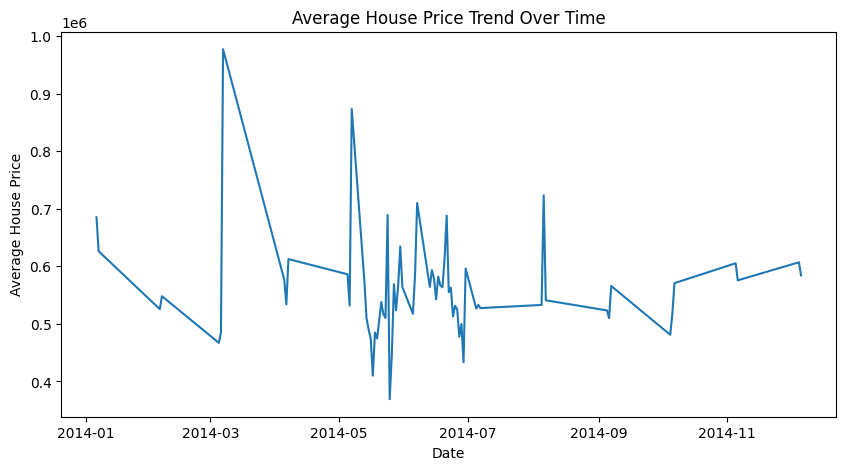

                  price  bedrooms  bathrooms  sqft_living  sqft_lot    floors  \
price          1.000000  0.200362   0.327098     0.430444  0.050469  0.151462   
bedrooms       0.200362  1.000000   0.545984     0.594866  0.068787  0.178312   
bathrooms      0.327098  0.545984   1.000000     0.761233  0.107875  0.486582   
sqft_living    0.430444  0.594866   0.761233     1.000000  0.210509  0.345433   
sqft_lot       0.050469  0.068787   0.107875     0.210509  1.000000  0.003968   
floors         0.151462  0.178312   0.486582     0.345433  0.003968  1.000000   
view           0.228522  0.111002   0.211996     0.310988  0.073884  0.031423   
sqft_above     0.367580  0.484701   0.689951     0.876450  0.216445  0.523353   
sqft_basement  0.210469  0.334124   0.298104     0.447169  0.034792 -0.255330   
yr_built       0.021962  0.142332   0.463921     0.287702  0.050569  0.469340   

                   view  sqft_above  sqft_basement  yr_built  
price          0.228522    0.367580       0.2

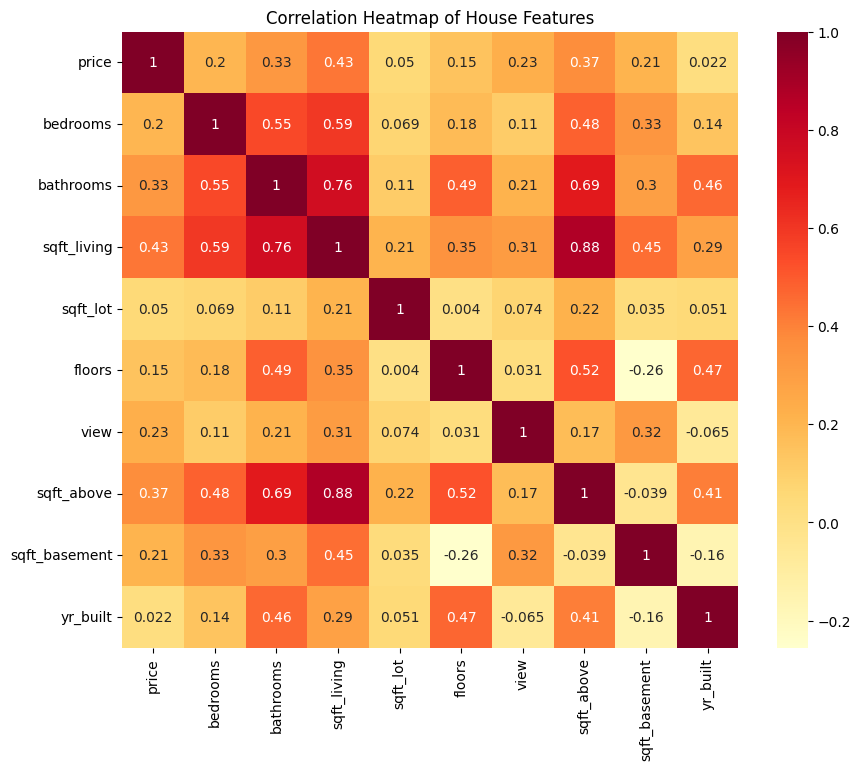

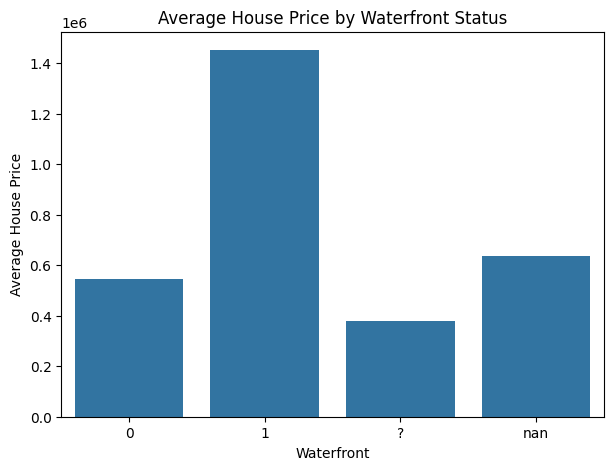

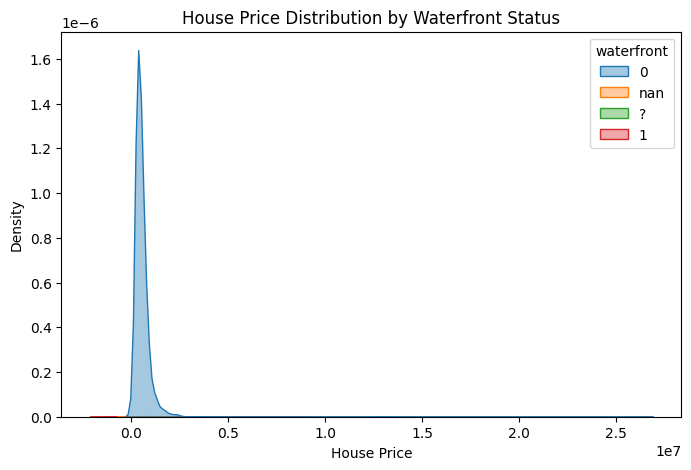

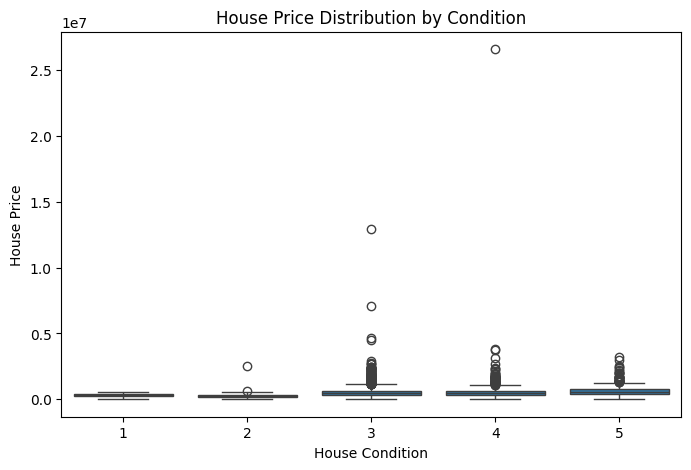

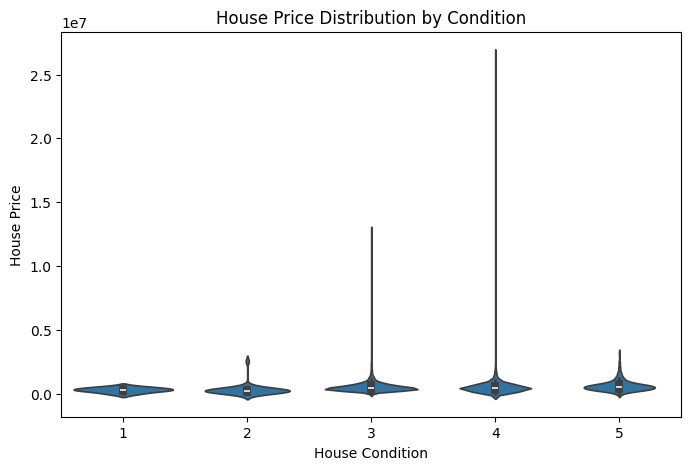

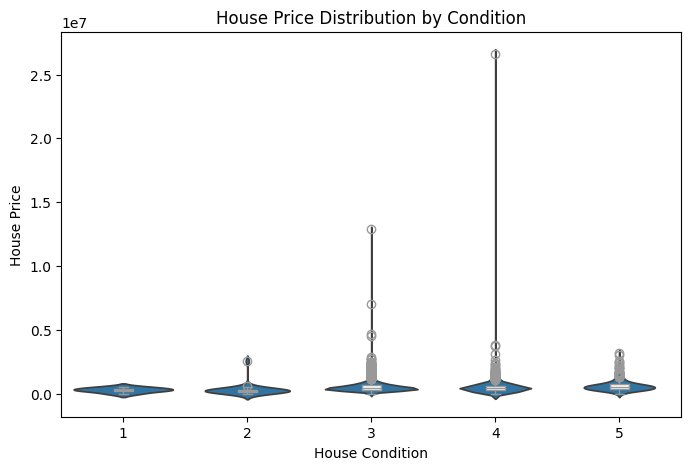

                  price  bedrooms  bathrooms  sqft_living  sqft_lot    floors  \
price          1.000000  0.200362   0.327098     0.430444  0.050469  0.151462   
bedrooms       0.200362  1.000000   0.545984     0.594866  0.068787  0.178312   
bathrooms      0.327098  0.545984   1.000000     0.761233  0.107875  0.486582   
sqft_living    0.430444  0.594866   0.761233     1.000000  0.210509  0.345433   
sqft_lot       0.050469  0.068787   0.107875     0.210509  1.000000  0.003968   
floors         0.151462  0.178312   0.486582     0.345433  0.003968  1.000000   
view           0.228522  0.111002   0.211996     0.310988  0.073884  0.031423   
sqft_above     0.367580  0.484701   0.689951     0.876450  0.216445  0.523353   
sqft_basement  0.210469  0.334124   0.298104     0.447169  0.034792 -0.255330   
yr_built       0.021962  0.142332   0.463921     0.287702  0.050569  0.469340   
yr_renovated  -0.028834 -0.060976  -0.216040    -0.122714 -0.022640 -0.234959   

                   view  sq

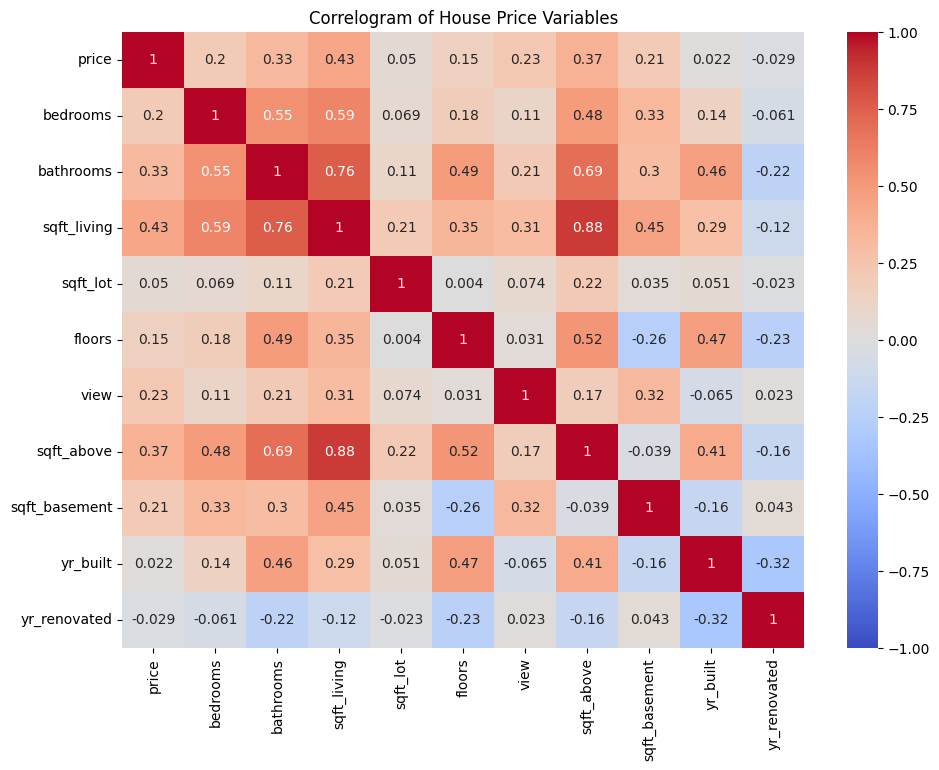

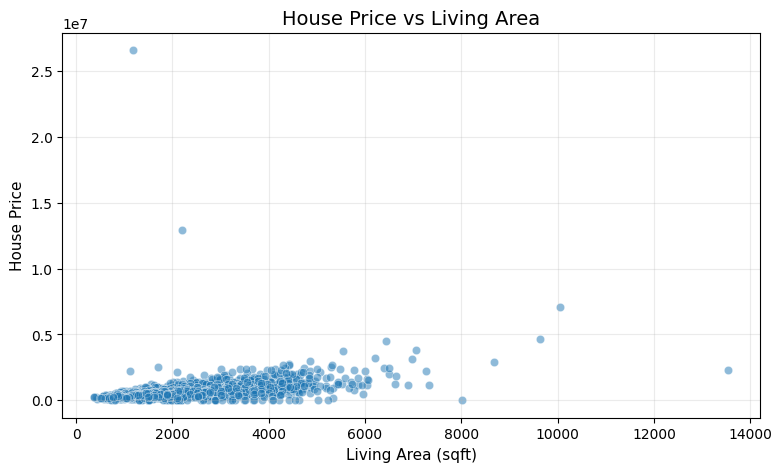

In [ ]:
# Assignment 4

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Load the dataset
url = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/house%20price.csv"
house = pd.read_csv(url)

print(house.head())
print(house.info())
print(house.describe(include="all"))

# Convert categorical variables and date column
house["waterfront"] = house["waterfront"].map(
    {0: "No", 1: "Yes"}
).fillna(house["waterfront"].astype(str))

house["condition"] = house["condition"].astype("category")
house["date"] = pd.to_datetime(house["date"], errors="coerce")

# 2. Contingency table and stacked bar plots
table_condition_waterfront = pd.crosstab(
    house["condition"], house["waterfront"]
)

print(table_condition_waterfront)

# Simple stacked bar plot
table_condition_waterfront.T.plot(
    kind="bar", stacked=True, figsize=(8, 5)
)

plt.title("House Condition vs Waterfront")
plt.xlabel("Waterfront")
plt.ylabel("Number of Houses")
plt.legend(title="Condition")
plt.show()

# Stacked bar plot using seaborn
plt.figure(figsize=(8, 5))
sns.countplot(data=house, x="waterfront", hue="condition")
plt.title("House Condition vs Waterfront")
plt.xlabel("Waterfront")
plt.ylabel("Number of Houses")
plt.legend(title="Condition")
plt.show()

# 3. Grouped / side-by-side bar plot
house["bedrooms_cat"] = house["bedrooms"].astype(str)

plt.figure(figsize=(10, 5))
sns.countplot(data=house, x="bedrooms_cat", hue="waterfront")
plt.title("Number of Bedrooms by Waterfront Status")
plt.xlabel("Number of Bedrooms")
plt.ylabel("Frequency")
plt.legend(title="Waterfront")
plt.show()

# 4. Scatter plot
plt.figure(figsize=(8, 5))

sns.regplot(
    data=house,
    x="sqft_living",
    y="price",
    scatter_kws={"alpha": 0.5},
    line_kws={"color": "red"}
)

plt.title("Relationship Between Living Area and House Price")
plt.xlabel("Living Area (sqft)")
plt.ylabel("House Price")
plt.show()

# 5. Line plot of average house price by date
daily_price = (
    house.groupby("date", as_index=False)["price"]
    .mean()
    .dropna()
    .sort_values("date")
)

plt.figure(figsize=(10, 5))
plt.plot(daily_price["date"], daily_price["price"])
plt.title("Average House Price Trend Over Time")
plt.xlabel("Date")
plt.ylabel("Average House Price")
plt.show()

# 6. Heatmap
numeric_columns = [
    "price", "bedrooms", "bathrooms", "sqft_living",
    "sqft_lot", "floors", "view", "sqft_above",
    "sqft_basement", "yr_built"
]

numeric_data = house[numeric_columns].select_dtypes(
    include=np.number
).dropna()

cor_matrix = numeric_data.corr()
print(cor_matrix)

plt.figure(figsize=(10, 8))
sns.heatmap(cor_matrix, annot=True, cmap="YlOrRd", square=True)
plt.title("Correlation Heatmap of House Features")
plt.show()

# 7. Bar chart: average house price by waterfront status
avg_price_waterfront = house.groupby(
    "waterfront", as_index=False
)["price"].mean()

plt.figure(figsize=(7, 5))
sns.barplot(data=avg_price_waterfront, x="waterfront", y="price")
plt.title("Average House Price by Waterfront Status")
plt.xlabel("Waterfront")
plt.ylabel("Average House Price")
plt.show()

# 8. Density plot
plt.figure(figsize=(8, 5))
sns.kdeplot(
    data=house, x="price", hue="waterfront",
    fill=True, alpha=0.4
)
plt.title("House Price Distribution by Waterfront Status")
plt.xlabel("House Price")
plt.ylabel("Density")
plt.show()

# 9. Box plot
plt.figure(figsize=(8, 5))
sns.boxplot(data=house, x="condition", y="price")
plt.title("House Price Distribution by Condition")
plt.xlabel("House Condition")
plt.ylabel("House Price")
plt.show()

# 10. Violin plot
plt.figure(figsize=(8, 5))
sns.violinplot(data=house, x="condition", y="price")
plt.title("House Price Distribution by Condition")
plt.xlabel("House Condition")
plt.ylabel("House Price")
plt.show()

# 11. Combined violin plot and box plot
plt.figure(figsize=(8, 5))

sns.violinplot(
    data=house, x="condition", y="price", inner=None
)

sns.boxplot(
    data=house, x="condition", y="price",
    width=0.15, color="white"
)

plt.title("House Price Distribution by Condition")
plt.xlabel("House Condition")
plt.ylabel("House Price")
plt.show()

# 12. Correlation matrix and correlogram
selected_columns = [
    "price", "bedrooms", "bathrooms", "sqft_living",
    "sqft_lot", "floors", "view", "sqft_above",
    "sqft_basement", "yr_built", "yr_renovated"
]

selected_numeric = house[selected_columns].select_dtypes(
    include=np.number
).dropna()

correlation_matrix = selected_numeric.corr()
print(correlation_matrix)

plt.figure(figsize=(11, 8))
sns.heatmap(
    correlation_matrix, annot=True,
    cmap="coolwarm", vmin=-1, vmax=1
)
plt.title("Correlogram of House Price Variables")
plt.show()

# 13. Graphical parameters: customize a plot
plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=house, x="sqft_living", y="price", alpha=0.5
)

plt.title("House Price vs Living Area", fontsize=14)
plt.xlabel("Living Area (sqft)", fontsize=11)
plt.ylabel("House Price", fontsize=11)
plt.grid(alpha=0.25)
plt.show()

            date      price  bedrooms  bathrooms  sqft_living  sqft_lot  \
0  02/05/14 0:00   313000.0         3       1.50         1340      7912   
1  02/05/14 0:00  2384000.0         5       2.50         3650      9050   
2  02/05/14 0:00   342000.0         3       2.00         1930     11947   
3  02/05/14 0:00   420000.0         3       2.25         2000      8030   
4  02/05/14 0:00   550000.0         4       2.50         1940     10500   

   floors waterfront  view  condition  sqft_above  sqft_basement  yr_built  \
0     1.5          0   0.0          3        1340              0      1955   
1     2.0          0   4.0          5        3370            280      1921   
2     1.0          0   0.0          4        1930              0      1966   
3     1.0          0   0.0          4        1000           1000      1963   
4     1.0          0   0.0          4        1140            800      1976   

   yr_renovated                    street       city  statezip country  
0      

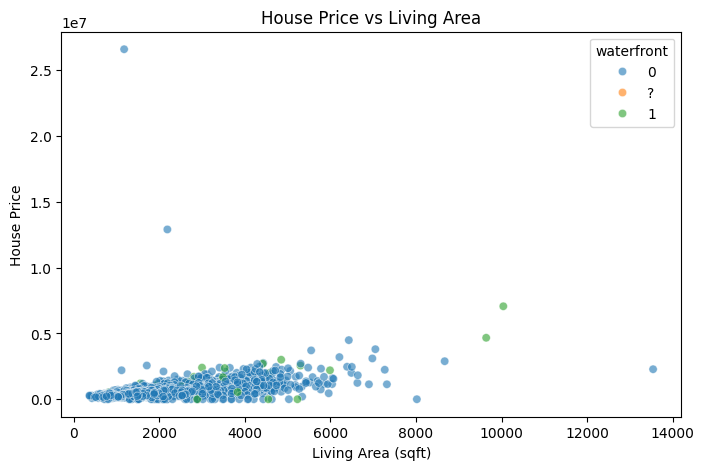

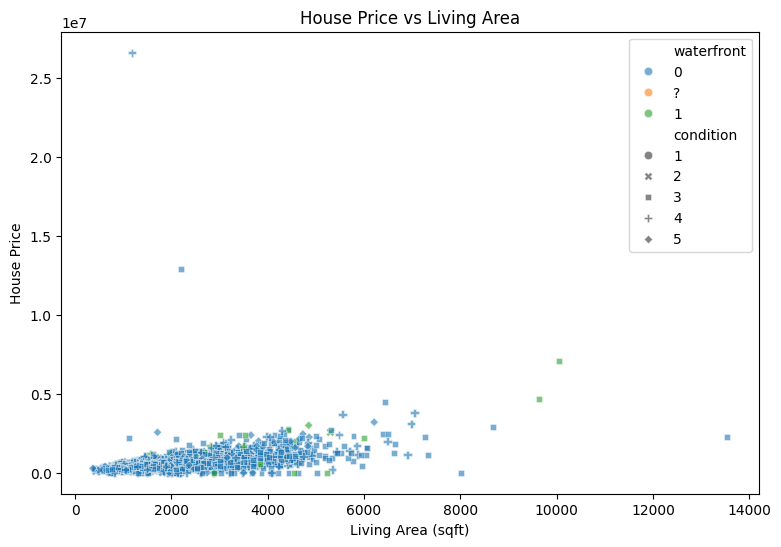

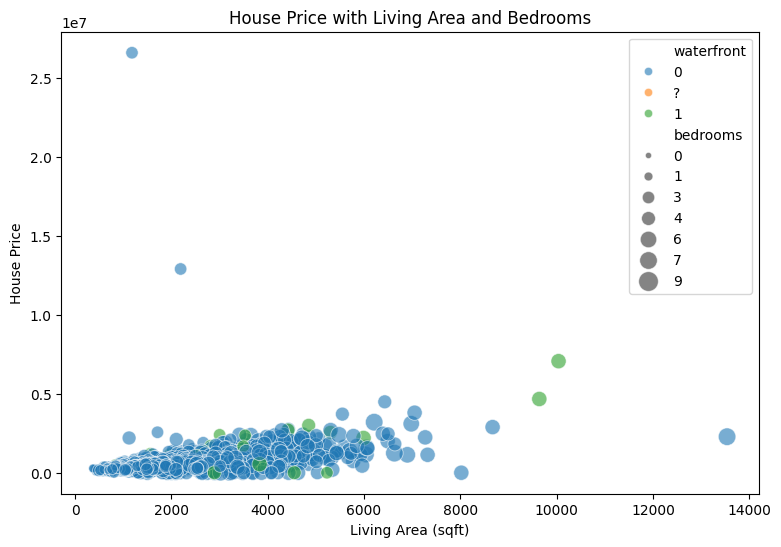

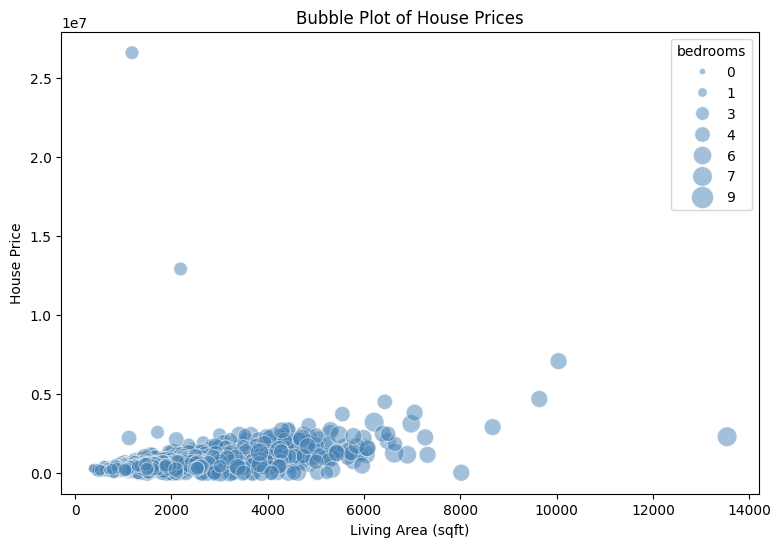

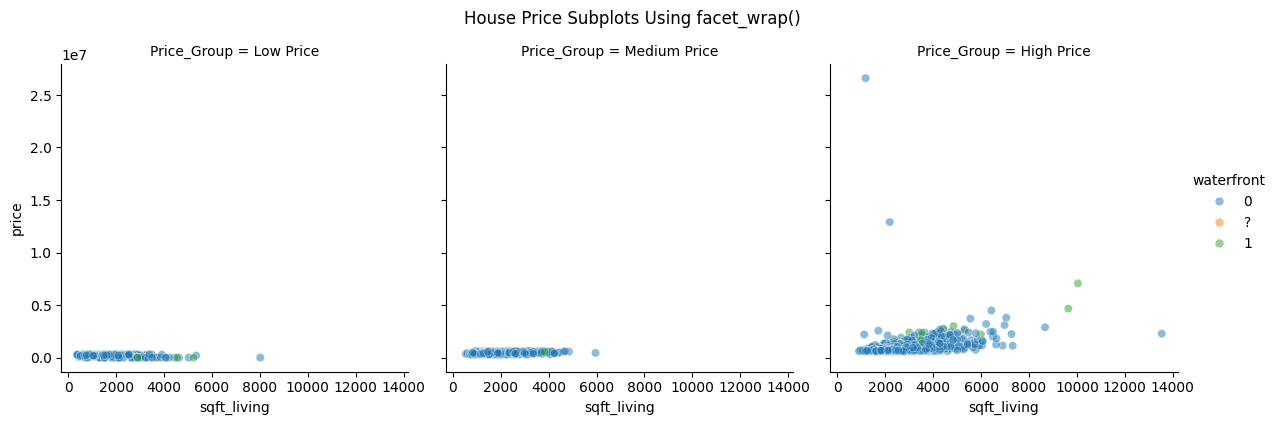

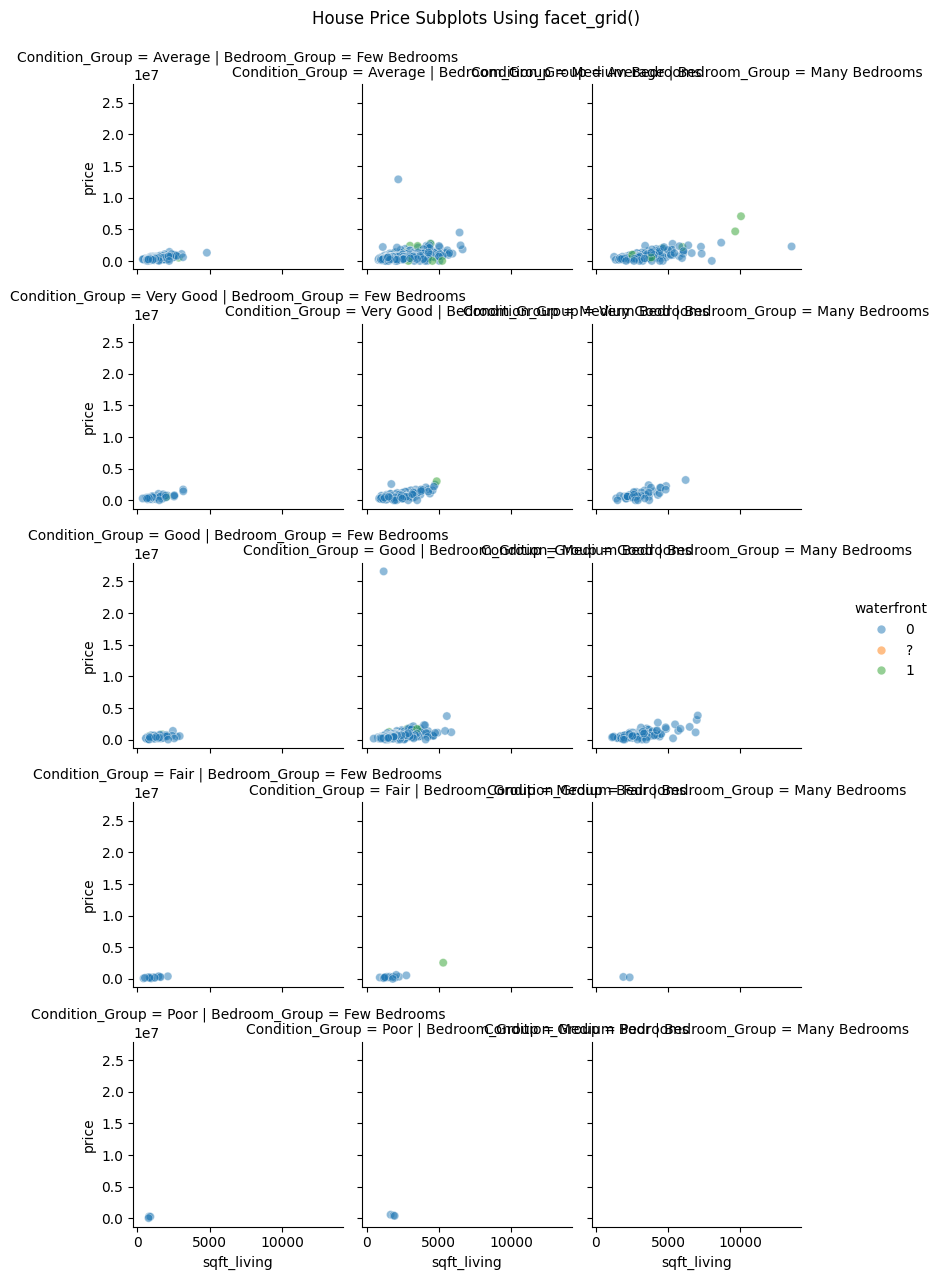

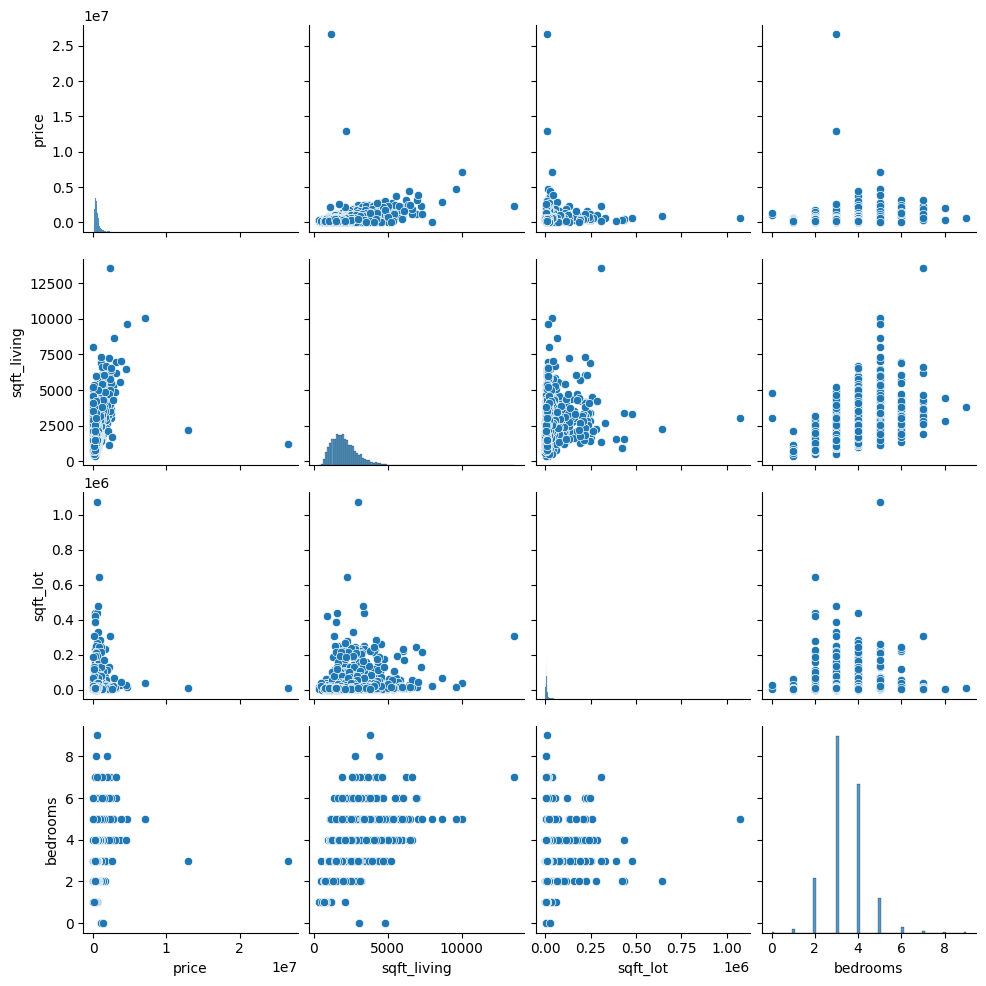

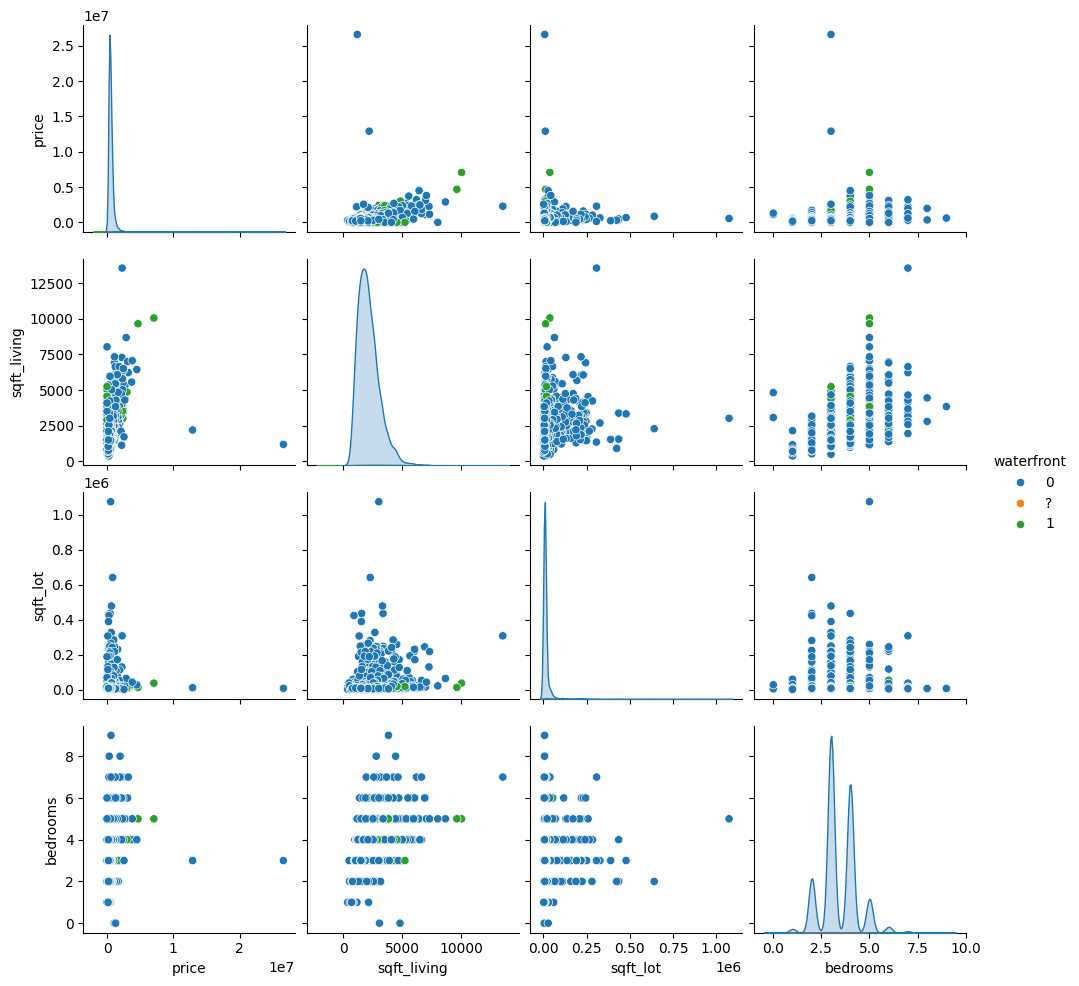

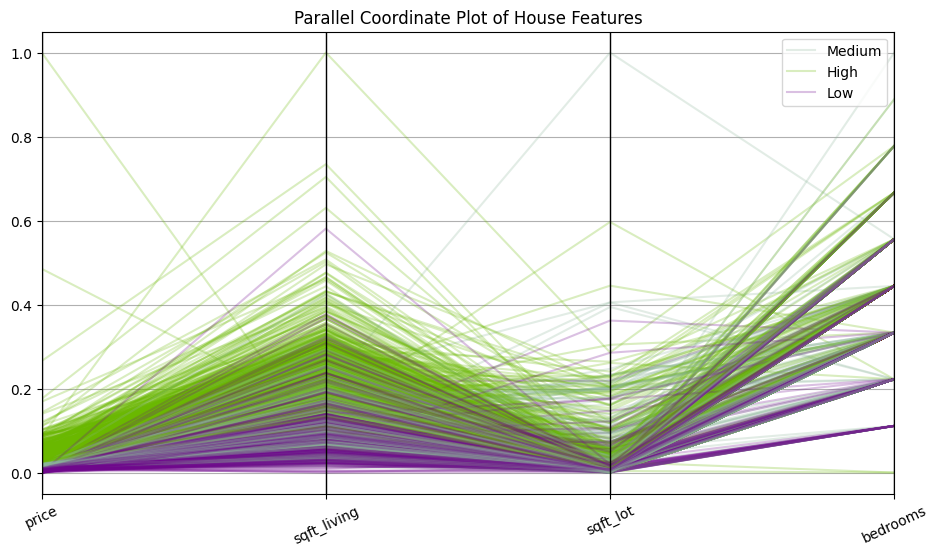

In [ ]:
# Assignment 5

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load dataset, view records, structure, summary and dimensions
url = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/house%20price.csv"
house = pd.read_csv(url)

print(house.head())
print(house.info())
print(house.describe(include="all"))
print("Dimensions:", house.shape)

# Identify numerical and categorical variables
numeric_variables = house.select_dtypes(include=np.number)
categorical_variables = house.select_dtypes(include=["object", "category"])

print("Numerical Variables:", numeric_variables.columns.tolist())
print("Categorical Variables:", categorical_variables.columns.tolist())

# 2. Scatter plot — three variables (color represents waterfront)
plt.figure(figsize=(8, 5))
sns.scatterplot(data=house, x="sqft_living", y="price",
                hue="waterfront", alpha=0.6)
plt.title("House Price vs Living Area")
plt.xlabel("Living Area (sqft)")
plt.ylabel("House Price")
plt.show()

# 3. Scatter plot — four variables (color = waterfront, shape = condition)
plt.figure(figsize=(9, 6))
sns.scatterplot(data=house, x="sqft_living", y="price",
                hue="waterfront", style="condition", alpha=0.6)
plt.title("House Price vs Living Area")
plt.xlabel("Living Area (sqft)")
plt.ylabel("House Price")
plt.show()

# 4. Scatter plot — color = waterfront, size = bedrooms
plt.figure(figsize=(9, 6))
sns.scatterplot(data=house, x="sqft_living", y="price",
                hue="waterfront", size="bedrooms",
                sizes=(20, 200), alpha=0.6)
plt.title("House Price with Living Area and Bedrooms")
plt.xlabel("Living Area (sqft)")
plt.ylabel("House Price")
plt.show()

# 5. Bubble plot — three numerical variables
plt.figure(figsize=(9, 6))
sns.scatterplot(data=house, x="sqft_living", y="price",
                size="bedrooms", sizes=(20, 250),
                color="steelblue", alpha=0.5)
plt.title("Bubble Plot of House Prices")
plt.xlabel("Living Area (sqft)")
plt.ylabel("House Price")
plt.show()

# 6. Subplots using facet_wrap()
house["Price_Group"] = pd.cut(
    house["price"],
    bins=[-np.inf, 300000, 600000, np.inf],
    labels=["Low Price", "Medium Price", "High Price"]
)

g = sns.relplot(
    data=house, x="sqft_living", y="price",
    hue="waterfront", col="Price_Group",
    kind="scatter", alpha=0.5, height=4
)
g.fig.suptitle("House Price Subplots Using facet_wrap()", y=1.05)
plt.show()

# 7. Subplots using facet_grid()
house["Bedroom_Group"] = pd.cut(
    house["bedrooms"],
    bins=[-np.inf, 2, 4, np.inf],
    labels=["Few Bedrooms", "Medium Bedrooms", "Many Bedrooms"]
)

house["Condition_Group"] = house["condition"].map({
    1: "Poor", 2: "Fair", 3: "Average",
    4: "Good", 5: "Very Good"
})

g = sns.relplot(
    data=house, x="sqft_living", y="price",
    hue="waterfront", row="Condition_Group",
    col="Bedroom_Group", kind="scatter",
    alpha=0.5, height=2.5
)
g.fig.suptitle("House Price Subplots Using facet_grid()", y=1.02)
plt.show()

# 8. Pairs plot using at least four numerical variables
pairs_data = house[
    ["price", "sqft_living", "sqft_lot", "bedrooms"]
].dropna()

sns.pairplot(pairs_data)
plt.show()

# Pairs plot with color based on waterfront
sns.pairplot(
    house[["price", "sqft_living", "sqft_lot",
           "bedrooms", "waterfront"]].dropna(),
    hue="waterfront"
)
plt.show()

# 9. Parallel coordinate plot
from pandas.plotting import parallel_coordinates

parallel_data = house[
    ["price", "sqft_living", "sqft_lot",
     "bedrooms", "waterfront"]
].dropna().copy()

parallel_data["price_group"] = pd.cut(
    parallel_data["price"],
    bins=[-np.inf, 300000, 600000, np.inf],
    labels=["Low", "Medium", "High"]
)

cols = ["price", "sqft_living", "sqft_lot", "bedrooms"]

# Normalize numerical columns for readability
for col in cols:
    low = parallel_data[col].min()
    high = parallel_data[col].max()

    if high != low:
        parallel_data[col] = (
            parallel_data[col] - low
        ) / (high - low)
    else:
        parallel_data[col] = 0

plt.figure(figsize=(11, 6))
parallel_coordinates(
    parallel_data[cols + ["price_group"]],
    "price_group", alpha=0.25
)
plt.title("Parallel Coordinate Plot of House Features")
plt.xticks(rotation=25)
plt.show()

1949-01-01    112.0
1949-02-01    118.0
1949-03-01    132.0
1949-04-01    129.0
1949-05-01    121.0
              ...  
1960-08-01    606.0
1960-09-01    508.0
1960-10-01    461.0
1960-11-01    390.0
1960-12-01    432.0
Freq: MS, Name: Passengers, Length: 144, dtype: float64
1949-01-01    112.0
1949-02-01    118.0
1949-03-01    132.0
1949-04-01    129.0
1949-05-01    121.0
Freq: MS, Name: Passengers, dtype: float64
1960-08-01    606.0
1960-09-01    508.0
1960-10-01    461.0
1960-11-01    390.0
1960-12-01    432.0
Freq: MS, Name: Passengers, dtype: float64
Start: 1949-01-01 00:00:00
End: 1960-12-01 00:00:00
Frequency: 12 observations per year
Class/type: <class 'pandas.core.series.Series'>
Start: 1949-01-01 00:00:00
End: 1960-12-01 00:00:00
Frequency: 12
Length: 144


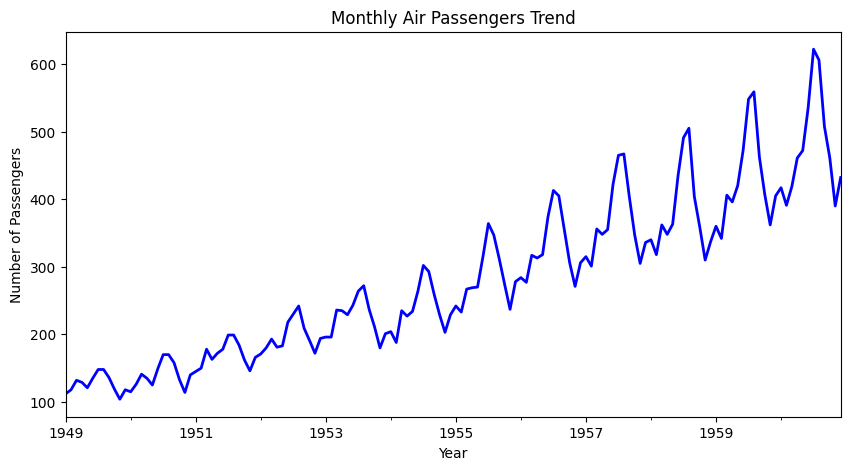

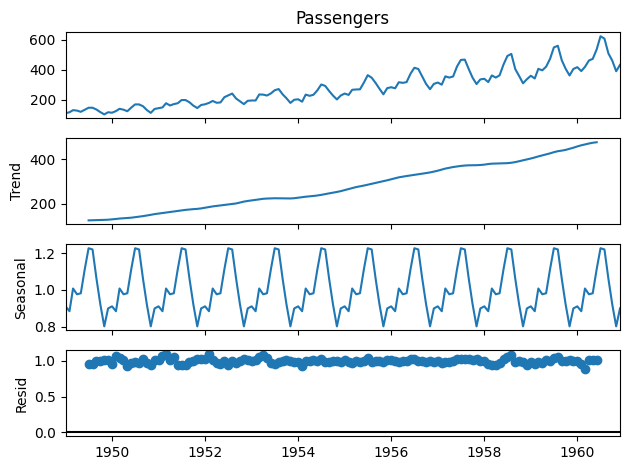

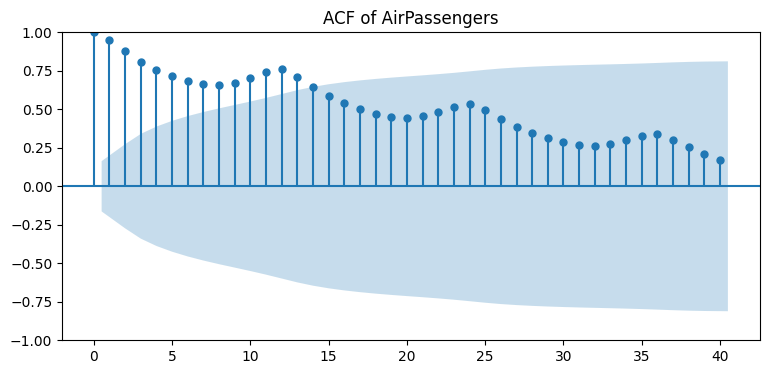

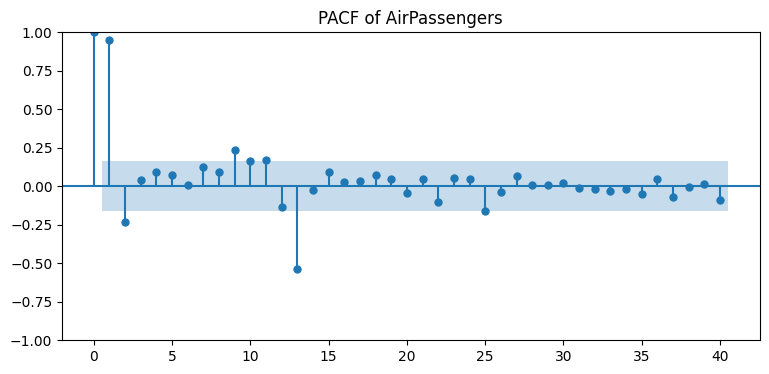

                                    SARIMAX Results                                     
Dep. Variable:                       Passengers   No. Observations:                  144
Model:             ARIMA(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood                -506.149
Date:                          Sat, 17 Oct 2026   AIC                           1022.299
Time:                                  07:05:33   BIC                           1036.675
Sample:                              01-01-1949   HQIC                          1028.140
                                   - 12-01-1960                                         
Covariance Type:                            opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.1272      0.356     -0.358      0.721      -0.825       0.570
ma.L1         -0.2148      0.325     -0.660      0.

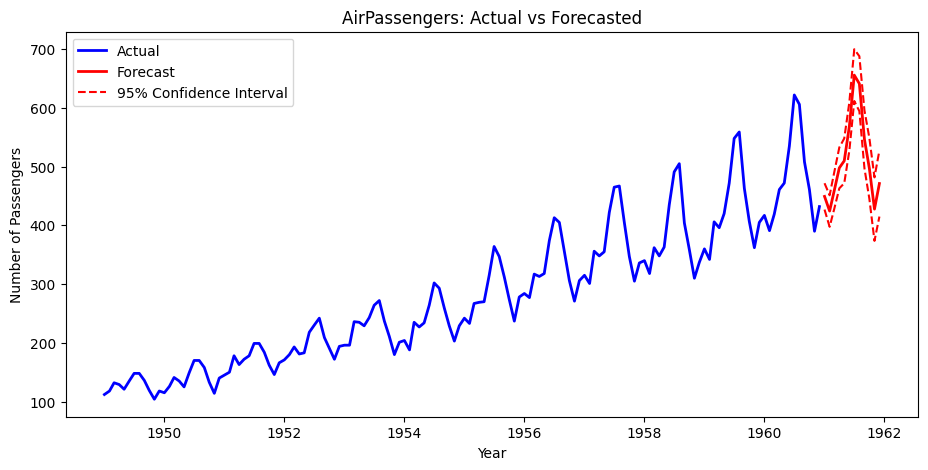

In [ ]:
# Assignment 6

import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA

# 1. Load the built-in AirPassengers dataset
air = sm.datasets.get_rdataset("AirPassengers").data

air_values = air["value"].astype(float)
air_dates = pd.date_range(
    start="1949-01-01",
    periods=len(air_values),
    freq="MS"
)

AirPassengers = pd.Series(
    air_values.to_numpy(),
    index=air_dates,
    name="Passengers"
)

# Display the dataset
print(AirPassengers)

# 2. Explore the first five and last five observations
print(AirPassengers.head(5))
print(AirPassengers.tail(5))

# 3. Identify the starting and ending time periods
print("Start:", AirPassengers.index[0])
print("End:", AirPassengers.index[-1])

# 4. Determine frequency and time-series characteristics
print("Frequency: 12 observations per year")
print("Class/type:", type(AirPassengers))
print("Start:", AirPassengers.index[0])
print("End:", AirPassengers.index[-1])
print("Frequency:", 12)
print("Length:", len(AirPassengers))

# 5. Visualize the monthly passenger trend
AirPassengers.plot(
    title="Monthly Air Passengers Trend",
    color="blue", linewidth=2, figsize=(10, 5)
)
plt.xlabel("Year")
plt.ylabel("Number of Passengers")
plt.show()

# 6. Decompose the time series into trend, seasonal and random components
decomposed = seasonal_decompose(
    AirPassengers, model="multiplicative", period=12
)
print(decomposed)

# 7. Plot the decomposed components
decomposed.plot()
plt.show()

# 8. Analyze autocorrelation and partial autocorrelation
fig, ax = plt.subplots(figsize=(9, 4))
plot_acf(AirPassengers, ax=ax, lags=40,
         title="ACF of AirPassengers")
plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
plot_pacf(AirPassengers, ax=ax, lags=40,
          method="ywm", title="PACF of AirPassengers")
plt.show()

# 9. Fit a seasonal ARIMA model
arima_model = ARIMA(
    AirPassengers,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12)
).fit()

# 10. Display fitted model parameters and summary
print(arima_model.summary())
print("Model coefficients:")
print(arima_model.params)

print("Variance-covariance matrix:")
print(arima_model.cov_params())

print("AIC:", arima_model.aic)

# 11. Forecast the next 12 months
forecast_result = arima_model.get_forecast(steps=12)

forecast_values = forecast_result.predicted_mean
forecast_se = forecast_result.se_mean

print("Forecasted values:")
print(forecast_values)

print("Prediction standard errors:")
print(forecast_se)

# 12. Visualize actual and forecasted passenger values
forecast_index = pd.date_range(
    start=AirPassengers.index[-1] + pd.offsets.MonthBegin(1),
    periods=12,
    freq="MS"
)

forecast_values.index = forecast_index
ci = forecast_result.conf_int()
ci.index = forecast_index

plt.figure(figsize=(11, 5))

plt.plot(
    AirPassengers.index, AirPassengers,
    color="blue", linewidth=2, label="Actual"
)

plt.plot(
    forecast_values.index, forecast_values,
    color="red", linewidth=2, label="Forecast"
)

plt.plot(
    forecast_values.index, ci.iloc[:, 0],
    color="red", linestyle="--", label="95% Confidence Interval"
)

plt.plot(
    forecast_values.index, ci.iloc[:, 1],
    color="red", linestyle="--"
)

plt.title("AirPassengers: Actual vs Forecasted")
plt.xlabel("Year")
plt.ylabel("Number of Passengers")
plt.legend()
plt.show()

            date      price  bedrooms  bathrooms  sqft_living  sqft_lot  \
0  02/05/14 0:00   313000.0         3       1.50         1340      7912   
1  02/05/14 0:00  2384000.0         5       2.50         3650      9050   
2  02/05/14 0:00   342000.0         3       2.00         1930     11947   
3  02/05/14 0:00   420000.0         3       2.25         2000      8030   
4  02/05/14 0:00   550000.0         4       2.50         1940     10500   

   floors waterfront  view  condition  sqft_above  sqft_basement  yr_built  \
0     1.5          0   0.0          3        1340              0      1955   
1     2.0          0   4.0          5        3370            280      1921   
2     1.0          0   0.0          4        1930              0      1966   
3     1.0          0   0.0          4        1000           1000      1963   
4     1.0          0   0.0          4        1140            800      1976   

   yr_renovated                    street       city  statezip country  
0      

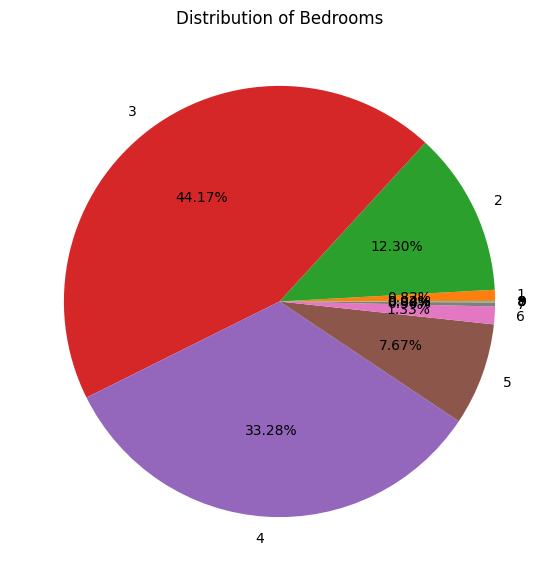

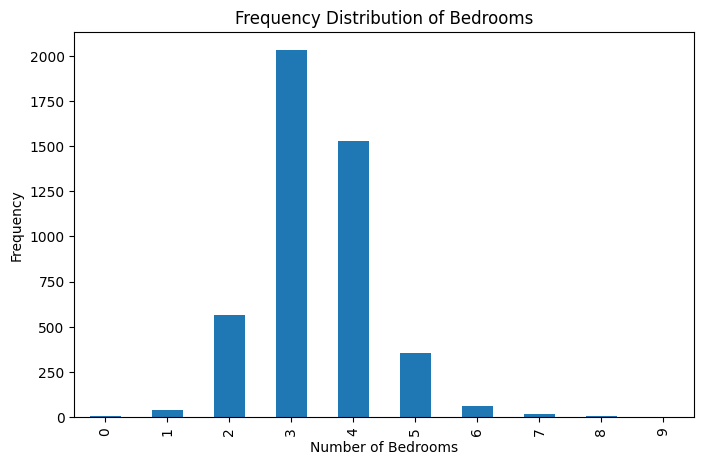

price
(-0.001, 1899285.714]           4543
(1899285.714, 3798571.429]        51
(3798571.429, 5697857.143]         3
(5697857.143, 7597142.857]         1
(7597142.857, 9496428.571]         0
(9496428.571, 11395714.286]        0
(11395714.286, 13295000.0]         1
(13295000.0, 15194285.714]         0
(15194285.714, 17093571.429]       0
(17093571.429, 18992857.143]       0
(18992857.143, 20892142.857]       0
(20892142.857, 22791428.571]       0
(22791428.571, 24690714.286]       0
(24690714.286, 26590000.0]         1
Name: count, dtype: int64


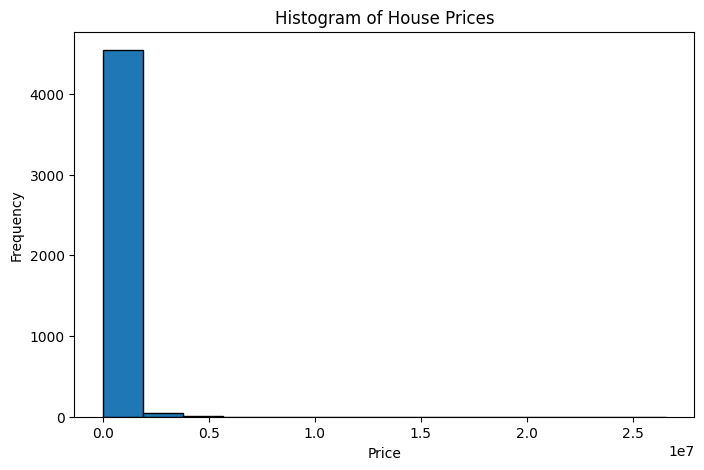

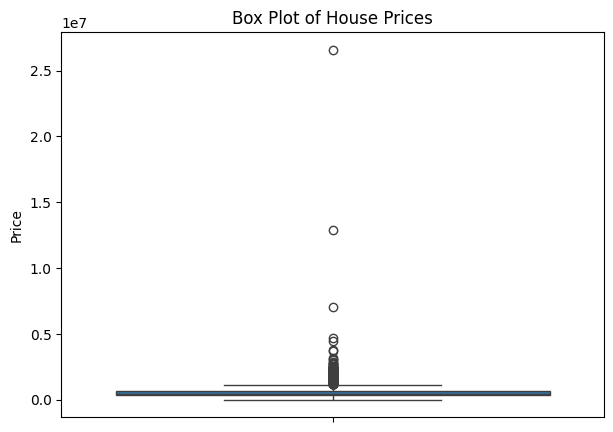

waterfront     0   1  ?
bedrooms               
0              2   0  0
1             38   0  0
2            556   7  1
3           2016  14  1
4           1524   6  0
5            348   5  0
6             60   1  0
7             14   0  0
8              2   0  0
9              1   0  0
waterfront           0         1         ?
bedrooms                                  
0           100.000000  0.000000  0.000000
1           100.000000  0.000000  0.000000
2            98.581560  1.241135  0.177305
3            99.261448  0.689316  0.049237
4            99.607843  0.392157  0.000000
5            98.583569  1.416431  0.000000
6            98.360656  1.639344  0.000000
7           100.000000  0.000000  0.000000
8           100.000000  0.000000  0.000000
9           100.000000  0.000000  0.000000
waterfront          0          1     ?
bedrooms                              
0            0.043850   0.000000   0.0
1            0.833151   0.000000   0.0
2           12.190309  21.212121  50.0
3

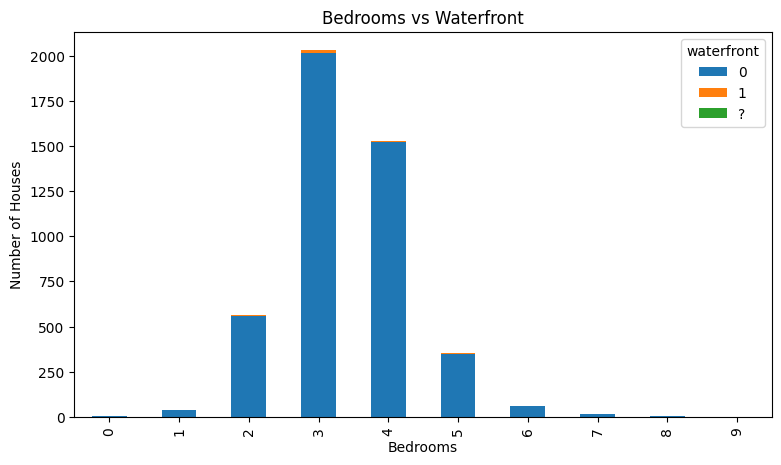

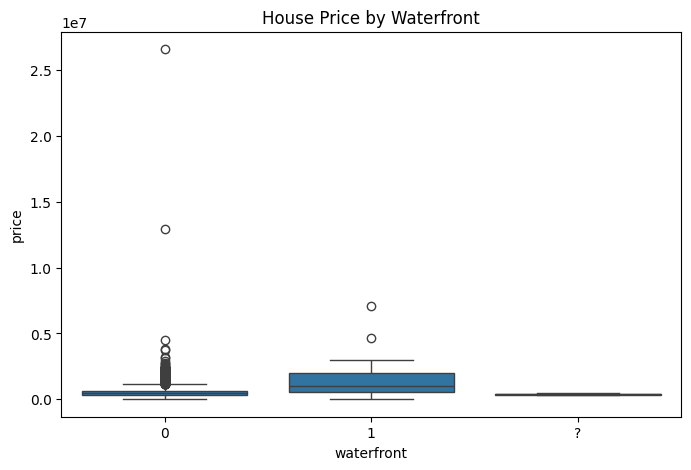

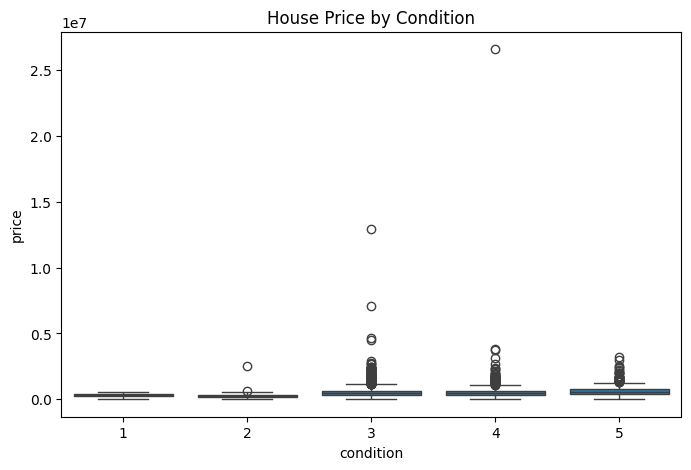

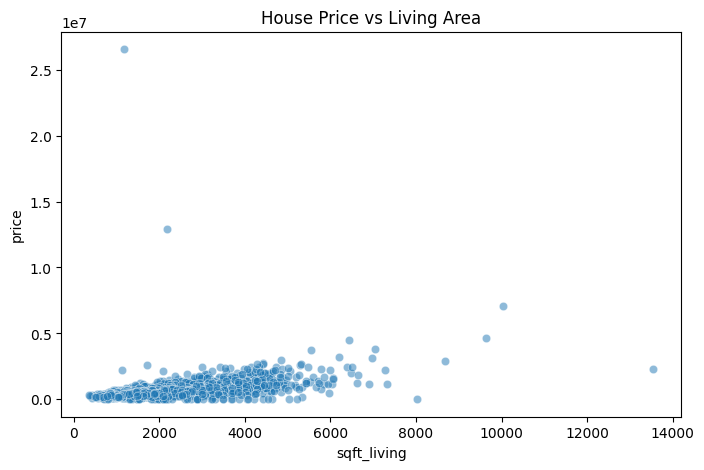

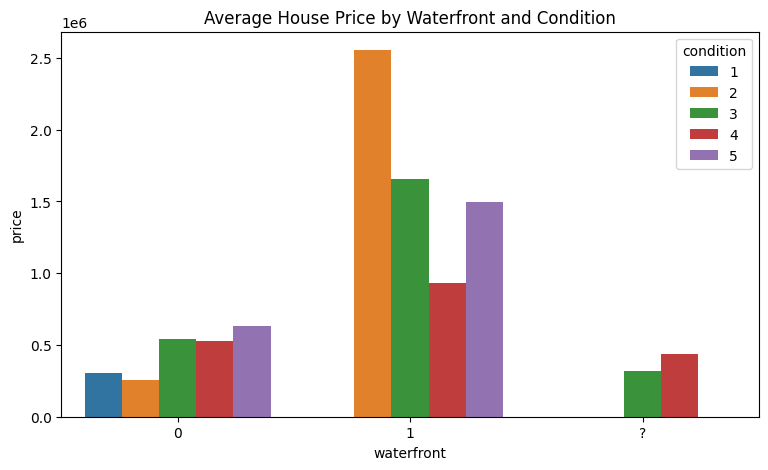

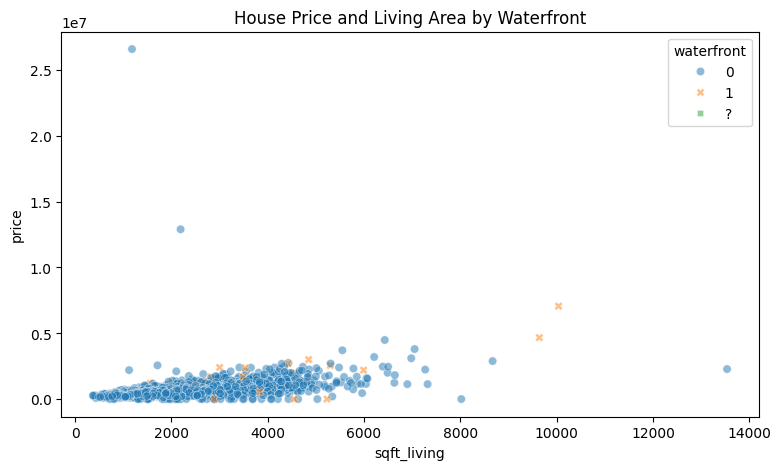

                  price  bathrooms  sqft_living  sqft_lot  sqft_above  \
price          1.000000   0.327110     0.430410  0.050451    0.367570   
bathrooms      0.327110   1.000000     0.761154  0.107837    0.689918   
sqft_living    0.430410   0.761154     1.000000  0.210538    0.876443   
sqft_lot       0.050451   0.107837     0.210538  1.000000    0.216455   
sqft_above     0.367570   0.689918     0.876443  0.216455    1.000000   
sqft_basement  0.210427   0.298020     0.447206  0.034842   -0.038723   
yr_built       0.021857   0.463498     0.287775  0.050706    0.408535   
yr_renovated  -0.028774  -0.215886    -0.122817 -0.022730   -0.160426   

               sqft_basement  yr_built  yr_renovated  
price               0.210427  0.021857     -0.028774  
bathrooms           0.298020  0.463498     -0.215886  
sqft_living         0.447206  0.287775     -0.122817  
sqft_lot            0.034842  0.050706     -0.022730  
sqft_above         -0.038723  0.408535     -0.160426  
sqft_basemen

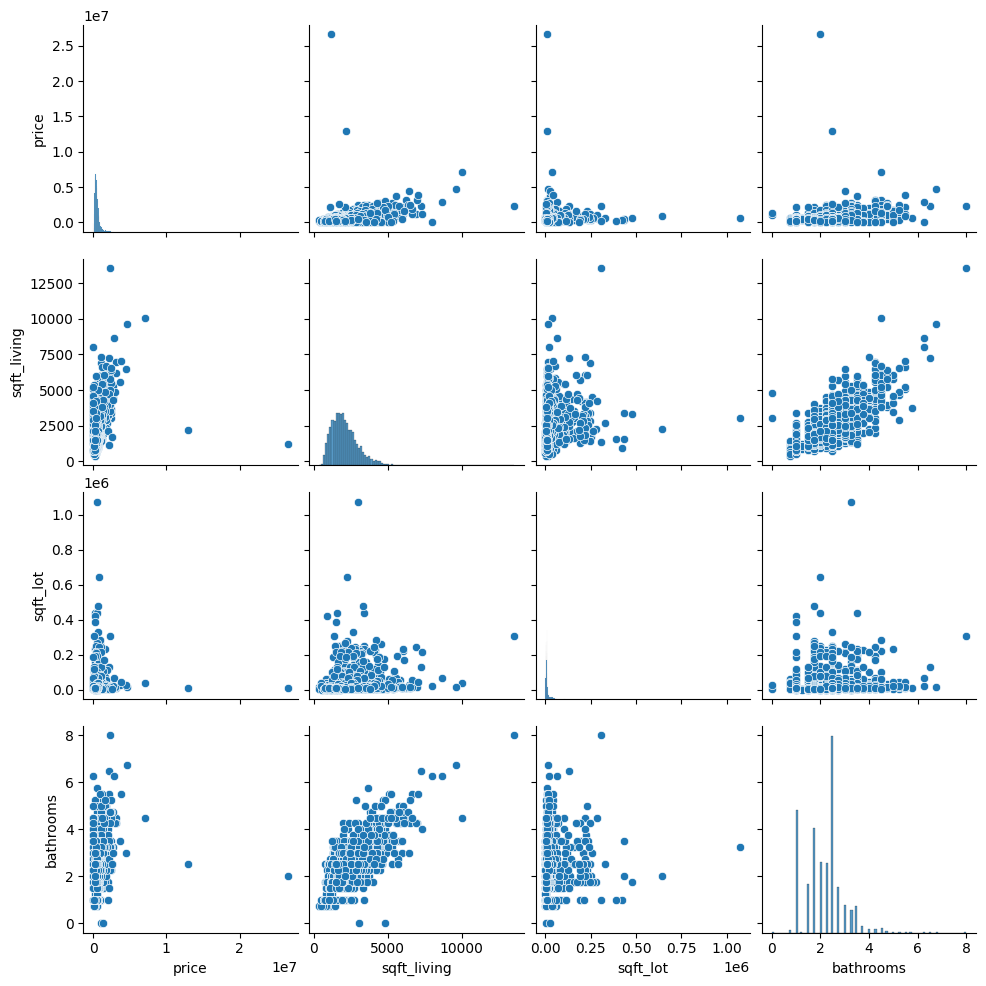

In [ ]:
# Assignment 7

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, kurtosis

# 1. Load the dataset
url = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/house%20price.csv"
house = pd.read_csv(url)

print(house.head())
print(house.info())
print(house.shape)
print(house.columns.tolist())

# Convert categorical variables to categories
for col in ["waterfront", "view", "condition",
            "bedrooms", "city", "floors"]:
    if col in house.columns:
        house[col] = house[col].astype("category")

# Check missing values
print(house.isna().sum())

# 2. Summary statistics: mean, median, minimum, maximum, range,
# variance, standard deviation, IQR, skewness and kurtosis
numeric_data = house[
    ["price", "bathrooms", "sqft_living", "sqft_lot",
     "sqft_above", "sqft_basement", "yr_built", "yr_renovated"]
].copy()

def summary_function(x):
    x = x.dropna()

    return pd.Series({
        "Mean": x.mean(),
        "Median": x.median(),
        "Minimum": x.min(),
        "Maximum": x.max(),
        "Range": x.max() - x.min(),
        "Variance": x.var(),
        "Standard_Deviation": x.std(),
        "IQR": x.quantile(0.75) - x.quantile(0.25),
        "Skewness": skew(x, bias=False),
        "Kurtosis": kurtosis(x, bias=False)
    })

# 3. Store values in a structured data frame
summary_statistics = pd.DataFrame({
    col: summary_function(numeric_data[col])
    for col in numeric_data.columns
}).T

summary_statistics.index.name = "Variable"
print(summary_statistics)

# 4. Frequency distribution: categorical variable Bedrooms
bedroom_frequency = house["bedrooms"].value_counts(
    dropna=False
).sort_index()

print("Frequency:\n", bedroom_frequency)

# Relative frequency
bedroom_relative_frequency = (
    bedroom_frequency / bedroom_frequency.sum()
)
print("Relative frequency:\n", bedroom_relative_frequency)

# Percentage
bedroom_percentage = bedroom_relative_frequency * 100
print("Percentage:\n", bedroom_percentage)

# Pie chart
plt.figure(figsize=(7, 7))
plt.pie(
    bedroom_frequency.values,
    labels=bedroom_frequency.index.astype(str),
    autopct="%1.2f%%"
)
plt.title("Distribution of Bedrooms")
plt.show()

# Bar plot
bedroom_frequency.plot(
    kind="bar",
    title="Frequency Distribution of Bedrooms",
    figsize=(8, 5)
)
plt.xlabel("Number of Bedrooms")
plt.ylabel("Frequency")
plt.show()

# 5. Numerical frequency distribution: variable Price
price = house["price"].dropna()

# Create bins using Sturges' rule
bins_count = int(np.ceil(1 + np.log2(len(price))))
breaks = np.histogram_bin_edges(price, bins=bins_count)

# Frequency distribution table
price_frequency = pd.cut(
    price, bins=breaks, include_lowest=True
).value_counts().sort_index()

print(price_frequency)

# Histogram
plt.figure(figsize=(8, 5))
plt.hist(price, bins=breaks, edgecolor="black")
plt.title("Histogram of House Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()

# Box plot
plt.figure(figsize=(7, 5))
sns.boxplot(y=house["price"])
plt.title("Box Plot of House Prices")
plt.ylabel("Price")
plt.show()

# 6. Two categorical variables: Bedrooms and Waterfront
contingency_table = pd.crosstab(
    house["bedrooms"], house["waterfront"]
)
print(contingency_table)

# Row percentages
print(
    pd.crosstab(
        house["bedrooms"], house["waterfront"],
        normalize="index"
    ) * 100
)

# Column percentages
print(
    pd.crosstab(
        house["bedrooms"], house["waterfront"],
        normalize="columns"
    ) * 100
)

# Overall percentages
print(
    pd.crosstab(
        house["bedrooms"], house["waterfront"],
        normalize="all"
    ) * 100
)

# 7. Stacked bar plot
contingency_table.plot(
    kind="bar", stacked=True, figsize=(9, 5)
)
plt.title("Bedrooms vs Waterfront")
plt.xlabel("Bedrooms")
plt.ylabel("Number of Houses")
plt.show()

# 8. Box plot of price by waterfront
plt.figure(figsize=(8, 5))
sns.boxplot(data=house, x="waterfront", y="price")
plt.title("House Price by Waterfront")
plt.show()

# 9. Box plot of price by condition
plt.figure(figsize=(8, 5))
sns.boxplot(data=house, x="condition", y="price")
plt.title("House Price by Condition")
plt.show()

# 10. Scatter plot of two numerical variables
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=house, x="sqft_living", y="price", alpha=0.5
)
plt.title("House Price vs Living Area")
plt.show()

# 11. Two categorical variables and one numerical variable
plt.figure(figsize=(9, 5))
sns.barplot(
    data=house, x="waterfront", y="price",
    hue="condition", errorbar=None
)
plt.title("Average House Price by Waterfront and Condition")
plt.show()

# 12. One categorical and two numerical variables
plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=house, x="sqft_living", y="price",
    hue="waterfront", style="waterfront", alpha=0.5
)
plt.title("House Price and Living Area by Waterfront")
plt.show()

# 13. Full correlation matrix
full_numeric = house.select_dtypes(include=np.number)
correlation_matrix = full_numeric.corr()
print(correlation_matrix)

# 14. Pairs plot / scatterplot matrix
pairs_columns = [
    "price", "sqft_living", "sqft_lot",
    "bedrooms", "bathrooms"
]

sns.pairplot(house[pairs_columns].dropna())
plt.show()

            date      price  bedrooms  bathrooms  sqft_living  sqft_lot  \
0  02/05/14 0:00   313000.0         3       1.50         1340      7912   
1  02/05/14 0:00  2384000.0         5       2.50         3650      9050   
2  02/05/14 0:00   342000.0         3       2.00         1930     11947   
3  02/05/14 0:00   420000.0         3       2.25         2000      8030   
4  02/05/14 0:00   550000.0         4       2.50         1940     10500   

   floors waterfront  view  condition  sqft_above  sqft_basement  yr_built  \
0     1.5          0   0.0          3        1340              0      1955   
1     2.0          0   4.0          5        3370            280      1921   
2     1.0          0   0.0          4        1930              0      1966   
3     1.0          0   0.0          4        1000           1000      1963   
4     1.0          0   0.0          4        1140            800      1976   

   yr_renovated                    street       city  statezip country  
0      

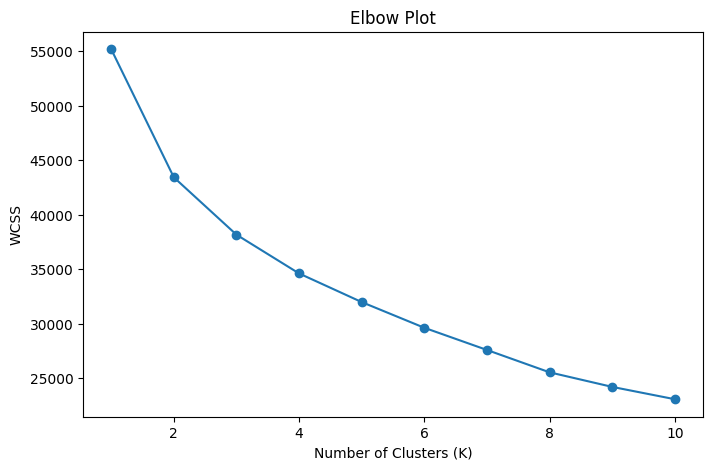

Cluster centers:
 [[-0.24176058 -0.35794265 -0.65745316 -0.55906648 -0.09135915 -0.71679155
  -0.17546595  0.27790531 -0.62627506  0.00316695 -0.58837459  0.25424057]
 [ 0.00692707  0.13517703  0.5068807   0.25801386  0.0057897   0.96440844
  -0.24340909 -0.479406    0.56991908 -0.52325547  0.87698798 -0.36459398]
 [ 0.94952407  1.05277744  1.20284873  1.51182018  0.34985174  0.14762676
   1.39128972  0.24092565  0.89970948  1.46614819 -0.12006416  0.01130043]]
Cluster assignments:
 [0 2 0 ... 1 0 1]
Cluster counts:
 0    2353
1    1659
2     587
Name: count, dtype: int64
            date      price  bedrooms  bathrooms  sqft_living  sqft_lot  \
0  02/05/14 0:00   313000.0         3       1.50         1340      7912   
1  02/05/14 0:00  2384000.0         5       2.50         3650      9050   
2  02/05/14 0:00   342000.0         3       2.00         1930     11947   
3  02/05/14 0:00   420000.0         3       2.25         2000      8030   
4  02/05/14 0:00   550000.0         4       2.

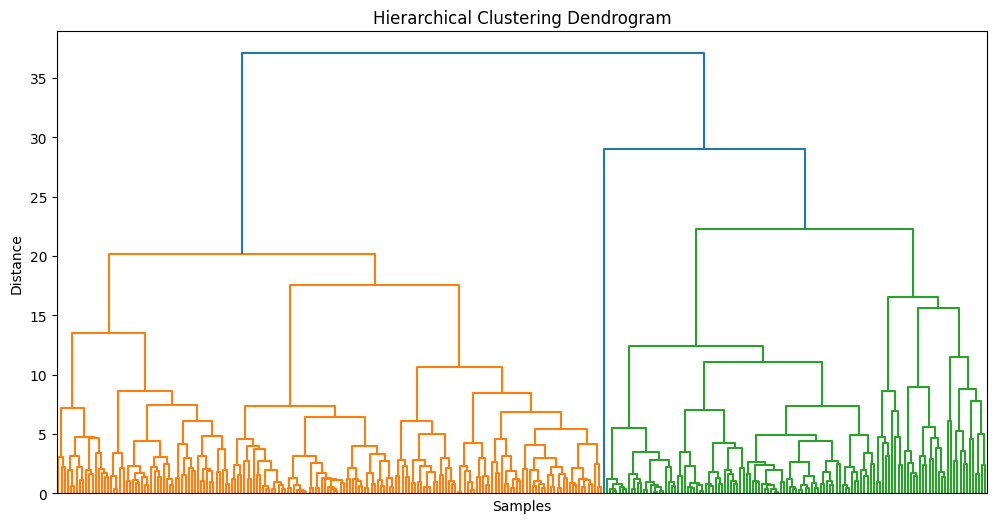

Cluster assignments: [0 2 0 ... 1 0 1]
0    2448
1    1737
2     414
Name: count, dtype: int64


In [ ]:
# Assignment 8

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import pdist

url = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/house%20price.csv"

# 1. Load the dataset
data = pd.read_csv(url)

# 2. View the dataset
print(data.head())

# 3. Check missing values
print(data.isna().sum())

# 4. Check the dependent variable distribution (table)
target_col = "Price" if "Price" in data.columns else "price"
print(data[target_col].value_counts(dropna=False))

# 5. Select only numerical features for K-Means clustering
num_data = data.select_dtypes(include=np.number).copy()

# Remove rows containing NA, NaN or Inf values
num_data = num_data.replace(
    [np.inf, -np.inf], np.nan
).dropna()

# 6. Standardize the data
scaled_data = StandardScaler().fit_transform(num_data)

# 7. Apply K-Means clustering for centers = 2
km2 = KMeans(n_clusters=2, random_state=123, n_init=10)
km2_labels = km2.fit_predict(scaled_data)

# 8. Display K-Means results
print("Cluster sizes:")
print(pd.Series(km2_labels).value_counts().sort_index())
print("WCSS:", km2.inertia_)

# 9. Display cluster centers
print(km2.cluster_centers_)

# 10. Calculate WCSS for K = 1 to 10
wcss = []

for k in range(1, 11):
    model = KMeans(
        n_clusters=k, random_state=123, n_init=10
    )
    model.fit(scaled_data)
    wcss.append(model.inertia_)

print("WCSS:", wcss)

# 11. Display the elbow plot
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Plot")
plt.show()

# 12. Apply K-Means clustering based on the elbow recommendation
# The original R code uses 3 clusters
km_elbow = KMeans(n_clusters=3, random_state=123, n_init=10)
elbow_labels = km_elbow.fit_predict(scaled_data)

print("Cluster centers:\n", km_elbow.cluster_centers_)
print("Cluster assignments:\n", elbow_labels)
print("Cluster counts:\n", pd.Series(elbow_labels).value_counts())

# 13. Load the dataset for hierarchical clustering
data = pd.read_csv(url)

# 14. View the dataset
print(data.head())

# 15. Check missing values
print(data.isna().sum())

# 16. Select only numerical attributes
num_data = data.select_dtypes(include=np.number).copy()
num_data = num_data.replace(
    [np.inf, -np.inf], np.nan
).dropna()

# 17. Standardize the data
scaled_data = StandardScaler().fit_transform(num_data)

# 18. Calculate Euclidean distance
distance = pdist(scaled_data, metric="euclidean")
print(distance[:10])

# 19. Perform hierarchical clustering using Ward's method
# Use the first 300 rows for a readable dendrogram
hc_linkage = linkage(scaled_data[:300], method="ward")

# 20. Plot the dendrogram
plt.figure(figsize=(12, 6))
dendrogram(hc_linkage, no_labels=True)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Samples")
plt.ylabel("Distance")
plt.show()

# 21. Divide the data into 3 clusters and display assignments
hc_model = AgglomerativeClustering(
    n_clusters=3, linkage="ward"
)
clusters = hc_model.fit_predict(scaled_data)
print("Cluster assignments:", clusters)

# 22. Display the number of samples in each cluster
print(pd.Series(clusters).value_counts().sort_index())

(4600, 18)
Rows: 4600
Columns: 18
Explained variance: [3.91913502 2.02255231 1.17562589 1.00266098 0.9267043  0.82988882
 0.67056363 0.44255026 0.41305541 0.37464045 0.22523277 0.        ]
Explained variance ratio: [0.32652357 0.16850938 0.09794752 0.08353691 0.07720857 0.06914236
 0.05586815 0.03687117 0.0344138  0.03121325 0.01876532 0.        ]
Cumulative variance: [0.32652357 0.49503295 0.59298047 0.67651738 0.75372595 0.82286831
 0.87873647 0.91560764 0.95002143 0.98123468 1.         1.        ]


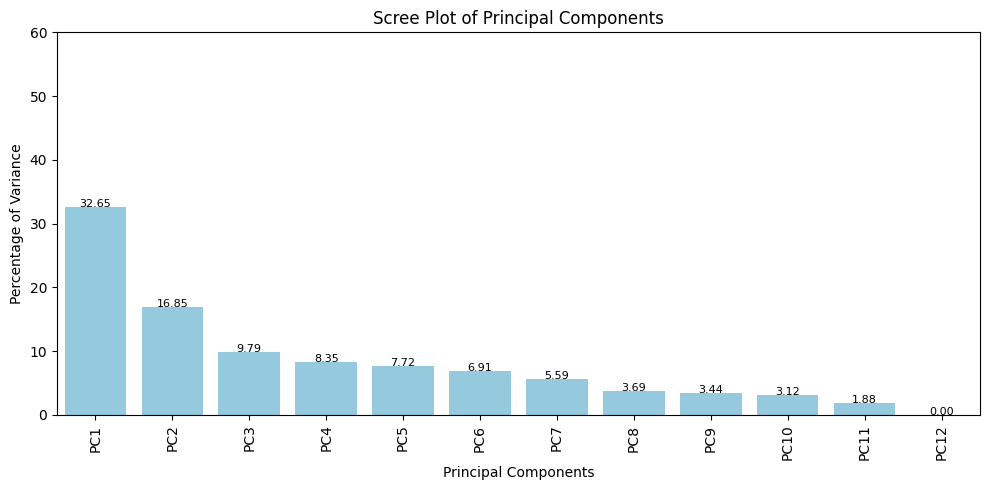

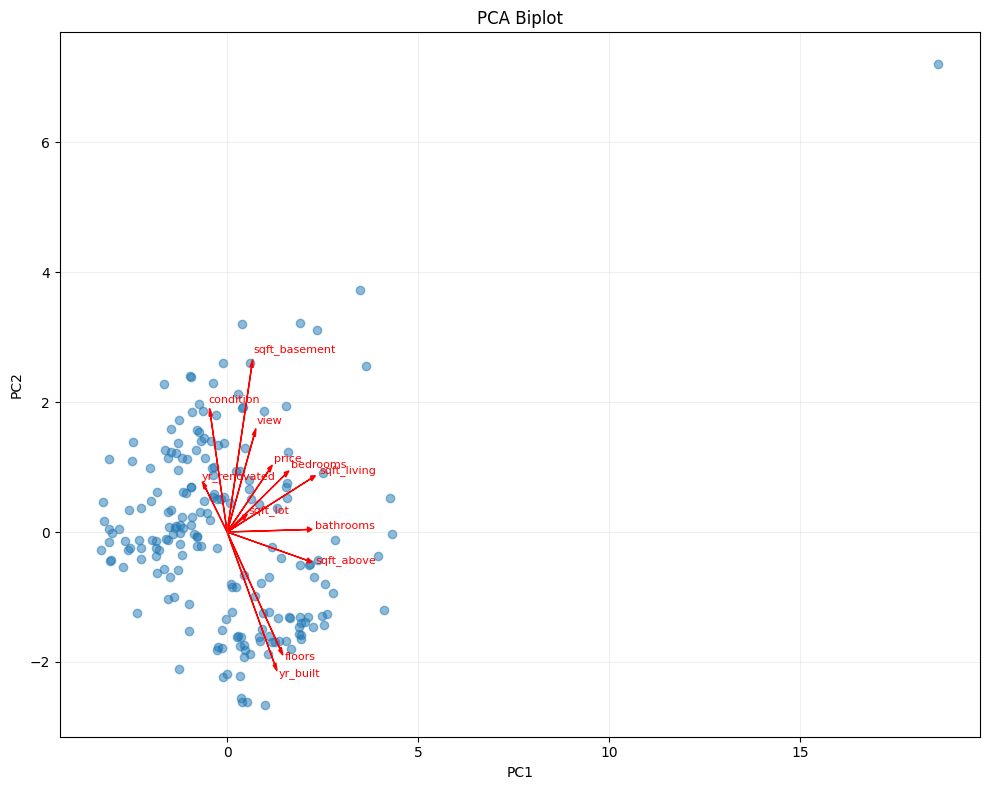

        PC1       PC2       PC3       PC4       PC5       PC6       PC7  \
0 -1.652209 -0.564573  1.256105 -0.069968 -0.005627 -0.309761 -0.344183   
1  3.476465  3.720501 -0.881266 -0.086284  4.094227 -0.721300 -2.188011   
2 -0.802301 -0.060741 -1.139433  0.348292 -0.016128 -0.214121 -0.070056   
3 -0.822277  1.265613 -1.204392 -0.296726 -0.520396  0.706771  0.927571   
4 -0.426904  1.400423  0.333542 -0.439537 -1.128940 -0.035494  0.371815   
5 -3.098898 -0.152715  1.331296  0.119563  0.622440 -0.290206  0.312240   

        PC8       PC9      PC10      PC11          PC12  
0  0.068790  0.219137 -0.005500 -0.042877  3.729180e-16  
1 -1.637073  0.853101  0.392018 -0.232208  6.714935e-15  
2 -0.569445 -0.828144 -0.112328  0.344464  1.956739e-15  
3  0.532247 -0.183803 -0.230687  0.160296 -3.170751e-15  
4  0.410935 -0.098622  1.218973  0.203080 -8.803164e-16  
5 -0.044000 -0.159080 -0.332576  0.129718  1.429655e-16  


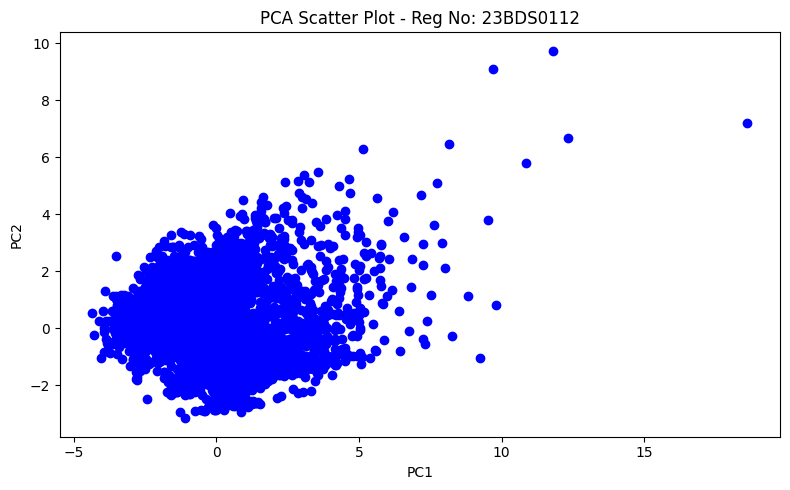

In [ ]:
# Assignment 9

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# 1. Load packages
# Python equivalents: pandas, numpy, matplotlib, seaborn and scikit-learn

# 2. Load dataset and display dimensions
url = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/house%20price.csv"
data = pd.read_csv(url)

print(data.shape)
print("Rows:", data.shape[0])
print("Columns:", data.shape[1])

# 3. Extract numeric columns, clean and normalize
numeric_data = data.select_dtypes(include=np.number)

# Remove columns with zero standard deviation
numeric_data = numeric_data.loc[
    :, numeric_data.std(skipna=True) > 0
]

# Remove rows with missing values
numeric_data = numeric_data.dropna()

# Standardize the data
data_scaled = StandardScaler().fit_transform(numeric_data)

# 4. Perform PCA and print summary
pca_result = PCA()
pca_scores_array = pca_result.fit_transform(data_scaled)

print("Explained variance:", pca_result.explained_variance_)
print("Explained variance ratio:", pca_result.explained_variance_ratio_)
print("Cumulative variance:", np.cumsum(pca_result.explained_variance_ratio_))

# 5. Scree plot with variance percentages and labels
variance = pca_result.explained_variance_ratio_ * 100

scree_data = pd.DataFrame({
    "PC": [f"PC{i}" for i in range(1, len(variance) + 1)],
    "Variance": variance
})

plt.figure(figsize=(10, 5))
sns.barplot(data=scree_data, x="PC", y="Variance", color="skyblue")

for i, value in enumerate(variance):
    plt.text(i, value, f"{value:.2f}", ha="center", fontsize=8)

plt.ylim(0, 60)
plt.title("Scree Plot of Principal Components")
plt.xlabel("Principal Components")
plt.ylabel("Percentage of Variance")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# 6. PCA biplot with labels and loading arrows
scores = pd.DataFrame(
    pca_scores_array,
    columns=[f"PC{i}" for i in range(1, pca_scores_array.shape[1] + 1)]
)

loadings = pca_result.components_.T

plt.figure(figsize=(10, 8))
plt.scatter(
    scores["PC1"].iloc[:200],
    scores["PC2"].iloc[:200],
    alpha=0.5
)

for i, name in enumerate(numeric_data.columns):
    plt.arrow(
        0, 0,
        loadings[i, 0] * 5,
        loadings[i, 1] * 5,
        color="red",
        head_width=0.08,
        length_includes_head=True
    )

    plt.text(
        loadings[i, 0] * 5.2,
        loadings[i, 1] * 5.2,
        name,
        color="red",
        fontsize=8
    )

plt.title("PCA Biplot")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# 7. Extract PCA scores and display first six rows
pca_scores = pd.DataFrame(
    pca_scores_array,
    columns=[f"PC{i}" for i in range(1, pca_scores_array.shape[1] + 1)]
)

print(pca_scores.head(6))

# 8. Scatter plot of PC1 vs PC2 with registration number in title
plt.figure(figsize=(8, 5))
plt.scatter(
    pca_scores["PC1"],
    pca_scores["PC2"],
    color="blue"
)

plt.title("PCA Scatter Plot - Reg No: 23BDS0112")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.tight_layout()
plt.show()

First five rows:


,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
0,02/05/14 0:00,313000.0,3,1.50,1340,7912,1.5,0,0.0,3,1340,0,1955,2005,18810 Densmore Ave N,Shoreline,WA 98133,USA
1,02/05/14 0:00,2384000.0,5,2.50,3650,9050,2.0,0,4.0,5,3370,280,1921,0,709 W Blaine St,Seattle,WA 98119,USA
2,02/05/14 0:00,342000.0,3,2.00,1930,11947,1.0,0,0.0,4,1930,0,1966,0,26206-26214 143rd Ave SE,Kent,WA 98042,USA
3,02/05/14 0:00,420000.0,3,2.25,2000,8030,1.0,0,0.0,4,1000,1000,1963,0,857 170th Pl NE,Bellevue,WA 98008,USA
4,02/05/14 0:00,550000.0,4,2.50,1940,10500,1.0,0,0.0,4,1140,800,1976,1992,9105 170th Ave NE,Redmond,WA 98052,USA



Dataset structure:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4600 entries, 0 to 4599
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           4600 non-null   object 
 1   price          4600 non-null   float64
 2   bedrooms       4600 non-null   int64  
 3   bathrooms      4600 non-null   float64
 4   sqft_living    4600 non-null   int64  
 5   sqft_lot       4600 non-null   int64  
 6   floors         4600 non-null   float64
 7   waterfront     4596 non-null   object 
 8   view           4599 non-null   float64
 9   condition      4600 non-null   int64  
 10  sqft_above     4600 non-null   int64  
 11  sqft_basement  4600 non-null   int64  
 12  yr_built       4600 non-null   int64  
 13  yr_renovated   4600 non-null   int64  
 14  street         4600 non-null   object 
 15  city           4600 non-null   object 
 16  statezip       4600 non-null   object 
 17  country        4599 non-null   o

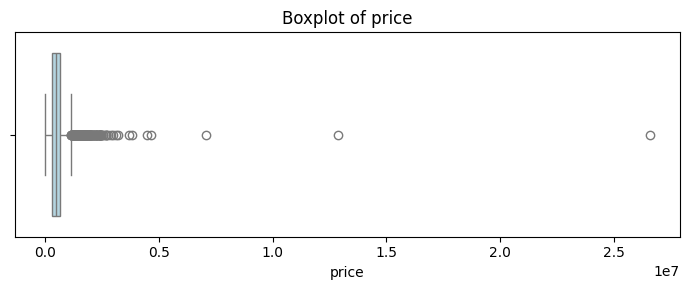

Outliers in bedrooms: 118


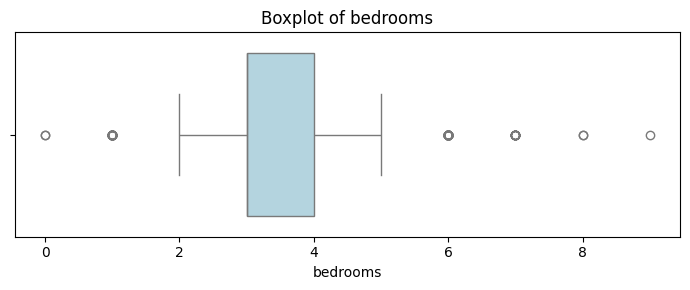

Outliers in bathrooms: 141


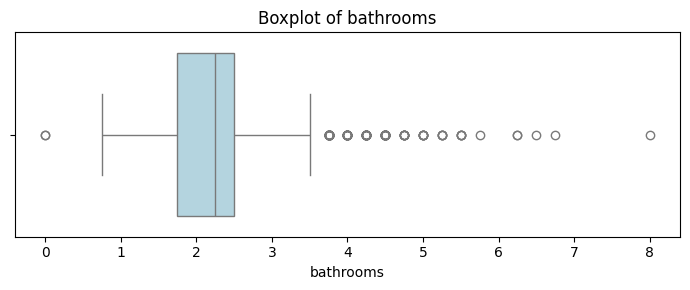

Outliers in sqft_living: 129


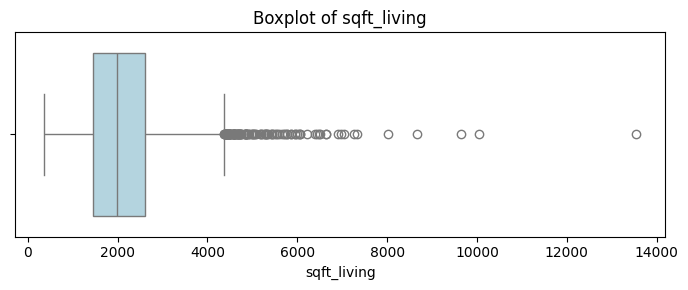

Outliers in sqft_lot: 541


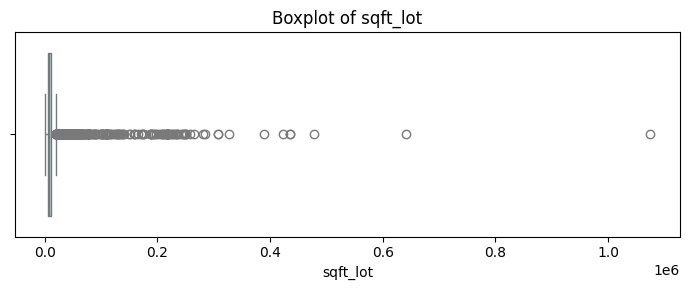

Outliers in floors: 0


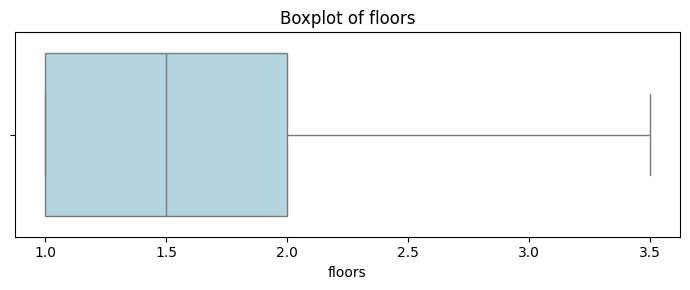

Outliers in view: 460


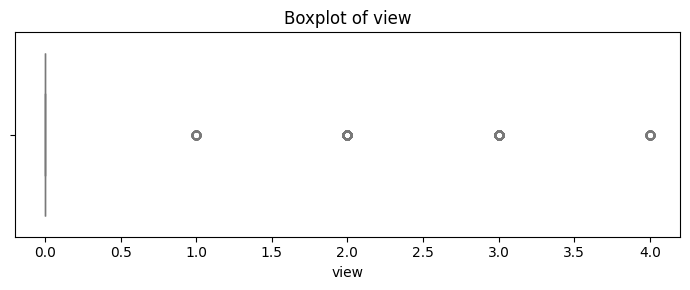

Outliers in condition: 6


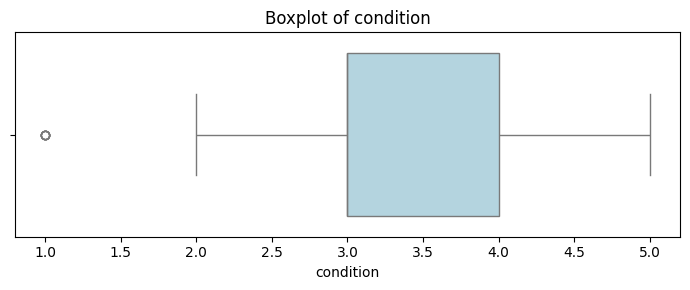

Outliers in sqft_above: 116


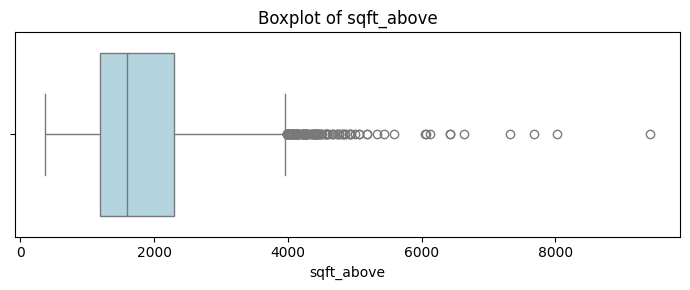

Outliers in sqft_basement: 82


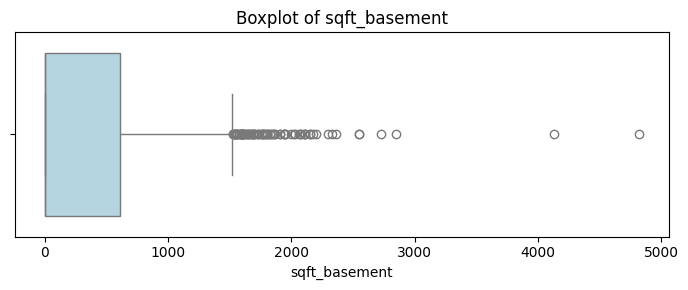

Outliers in yr_built: 0


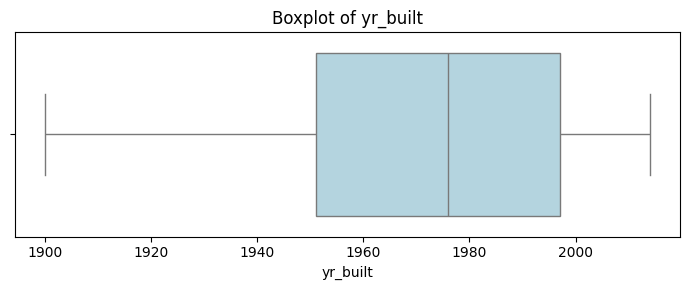

Outliers in yr_renovated: 0


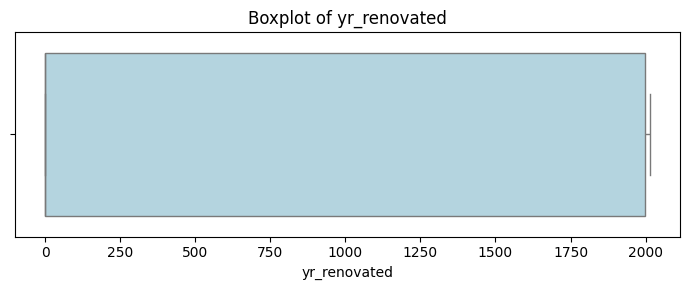

Independent variable (X): sqft_living
Dependent variable (Y): price
Regression dataset shape: (4600, 2)

Statistics for sqft_living
Mean: 2139.3469565217392
Median: 1980.0
Variance: 927767.5625695573
Standard Deviation: 963.2069157608646

Statistics for price
Mean: 551962.9884730434
Median: 460943.46155
Variance: 317909571796.05096
Standard Deviation: 563834.7025468111


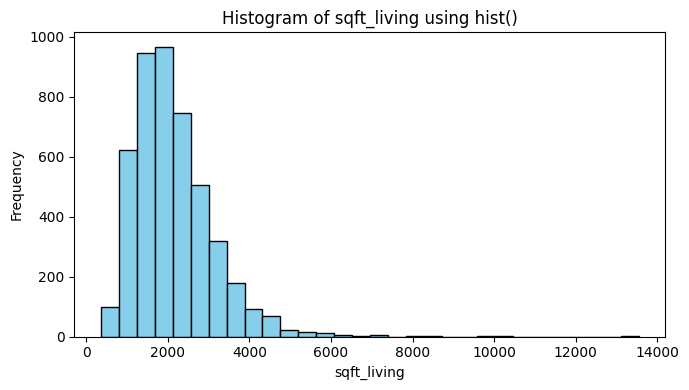

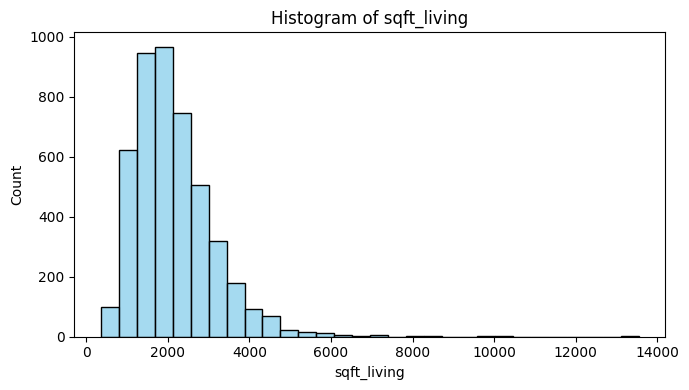

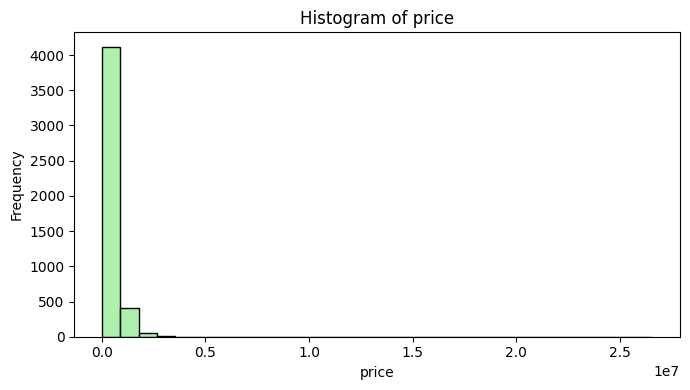

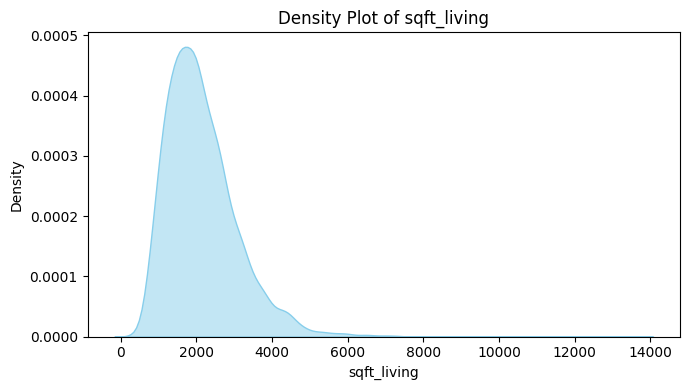

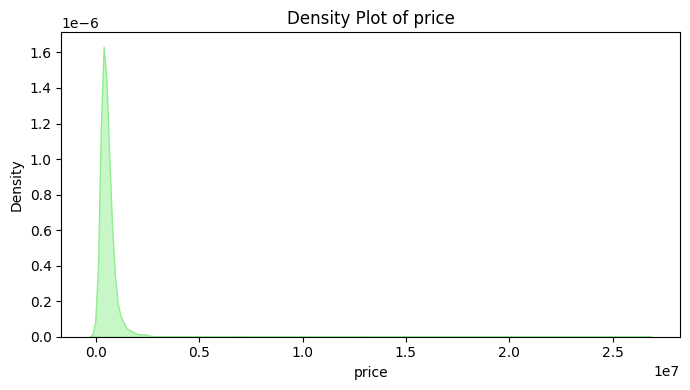

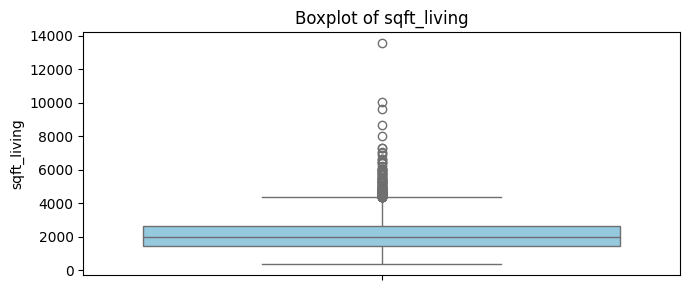

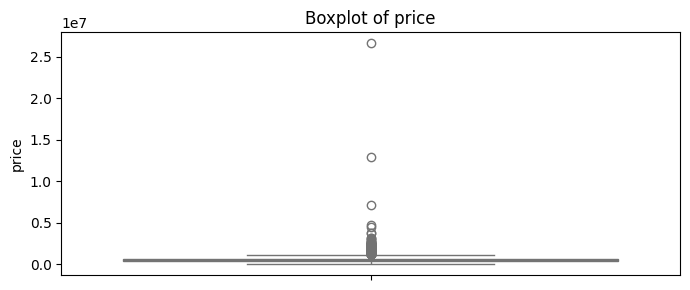

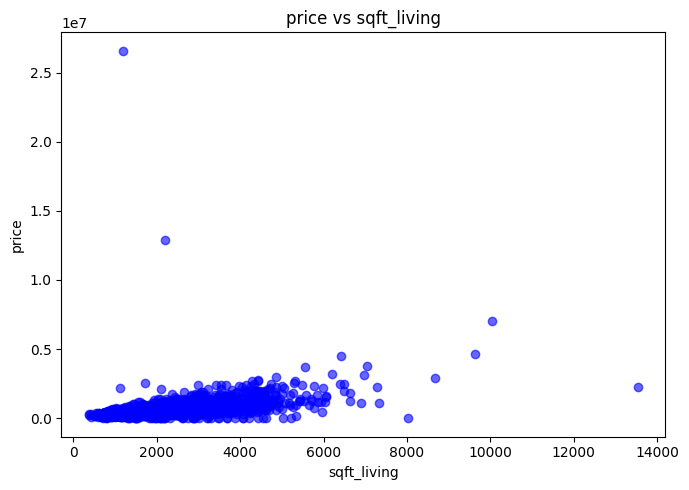

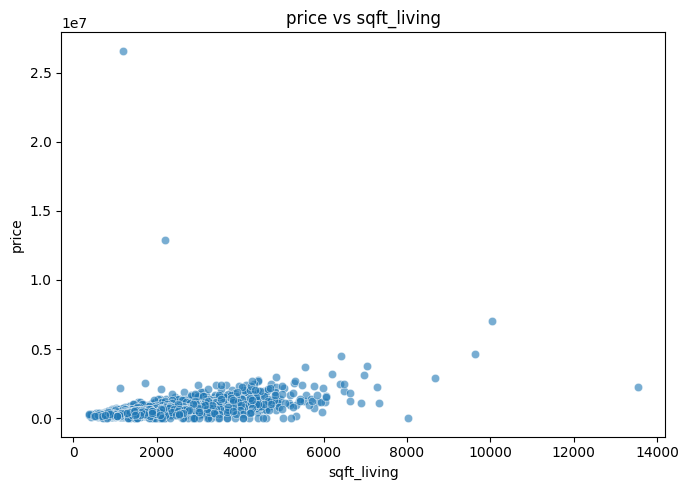

Pearson Correlation Coefficient: 0.43041002543280205
Correlation p-value: 7.549895922182314e-207


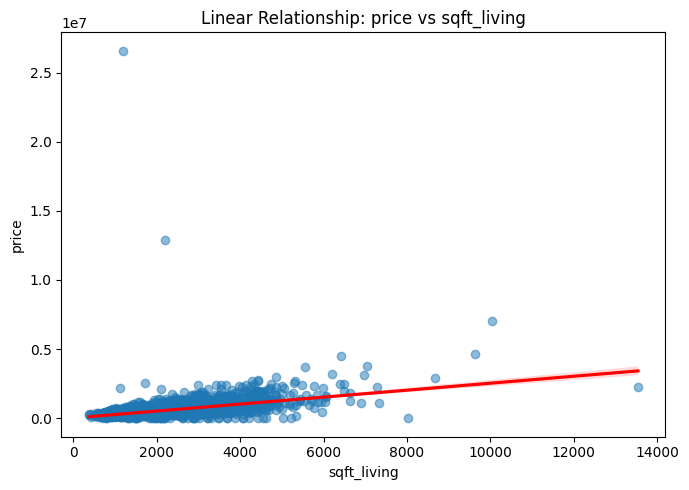

Training observations: 3680
Testing observations: 920
Simple Linear Regression model trained successfully.
                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.462
Model:                            OLS   Adj. R-squared:                  0.462
Method:                 Least Squares   F-statistic:                     3156.
Date:                Sun, 01 Nov 2026   Prob (F-statistic):               0.00
Time:                        06:13:59   Log-Likelihood:                -51332.
No. Observations:                3680   AIC:                         1.027e+05
Df Residuals:                    3678   BIC:                         1.027e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-----------------------

,Actual,Predicted,Residual
3683,544000.0,364098.331631,179901.668369
4411,0.0,508399.107079,-508399.107079
2584,1712500.0,759589.345822,952910.654178
69,365000.0,561843.838726,-196843.838726
1844,275000.0,433576.482773,-158576.482773


Mean Absolute Error (MAE): 225375.2534583526
Mean Squared Error (MSE): 990204087727.0969
Root Mean Squared Error (RMSE): 995089.9897632862
Mean Absolute Percentage Error (MAPE): 37.35182195238937 %


In [2]:
#Assignment 10

# Q1. Load the dataset and import the required libraries.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
import statsmodels.api as sm
from scipy.stats import pearsonr

url = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/house%20price.csv"
data = pd.read_csv(url)

print("First five rows:")
display(data.head())

print("\nDataset structure:")
data.info()

print("\nColumn names:")
print(data.columns.tolist())


# Q2. Identify missing values and handle them appropriately.
# Numeric columns: median. Categorical columns: mode.

print("Missing values before handling:")
print(data.isna().sum())

for col in data.columns:
    if pd.api.types.is_numeric_dtype(data[col]):
        if data[col].isna().any():
            data[col] = data[col].fillna(data[col].median())
    else:
        if data[col].isna().any():
            modes = data[col].mode(dropna=True)
            if not modes.empty:
                data[col] = data[col].fillna(modes.iloc[0])

print("\nMissing values after handling:")
print(data.isna().sum())


# Q3. Identify and remove duplicate records.

print("Duplicate records before removal:", data.duplicated().sum())

data = data.drop_duplicates().copy()

print("Duplicate records after removal:", data.duplicated().sum())


# Q4. Detect outliers in numeric columns using the IQR method
# and visualize them using boxplots.

numeric_columns = data.select_dtypes(include=np.number).columns.tolist()

for col in numeric_columns:
    q1 = data[col].quantile(0.25)
    q3 = data[col].quantile(0.75)
    iqr_value = q3 - q1

    lower_limit = q1 - 1.5 * iqr_value
    upper_limit = q3 + 1.5 * iqr_value

    outliers = data.loc[
        (data[col] < lower_limit) | (data[col] > upper_limit), col
    ]

    print(f"Outliers in {col}: {len(outliers)}")

    plt.figure(figsize=(7, 3))
    sns.boxplot(x=data[col], color="lightblue")
    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()


# Q5. Select one numeric independent variable (X) and one
# numeric dependent variable (Y).

if {"sqft_living", "price"}.issubset(data.columns):
    X_name = "sqft_living"
    Y_name = "price"
elif {"area", "price"}.issubset(data.columns):
    X_name = "area"
    Y_name = "price"
else:
    raise ValueError("The expected regression columns were not found.")

reg_data = data[[X_name, Y_name]].dropna().copy()

X = reg_data[X_name]
Y = reg_data[Y_name]

print("Independent variable (X):", X_name)
print("Dependent variable (Y):", Y_name)
print("Regression dataset shape:", reg_data.shape)


# Q6. Calculate mean, median, variance and standard deviation
# for the selected numerical variables.

for variable_name, values in [(X_name, X), (Y_name, Y)]:
    print(f"\nStatistics for {variable_name}")
    print("Mean:", values.mean())
    print("Median:", values.median())
    print("Variance:", values.var())
    print("Standard Deviation:", values.std())


# Q7. Generate a histogram of the independent variable using
# matplotlib hist() and seaborn.

plt.figure(figsize=(7, 4))
plt.hist(X, bins=30, color="skyblue", edgecolor="black")
plt.title(f"Histogram of {X_name} using hist()")
plt.xlabel(X_name)
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
sns.histplot(data=reg_data, x=X_name, bins=30, color="skyblue")
plt.title(f"Histogram of {X_name}")
plt.tight_layout()
plt.show()


# Q8. Generate a histogram of the dependent variable using
# seaborn histplot().

plt.figure(figsize=(7, 4))
sns.histplot(data=reg_data, x=Y_name, bins=30, color="lightgreen")
plt.title(f"Histogram of {Y_name}")
plt.xlabel(Y_name)
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


# Q9. Visualize the distribution of both variables using density plots.

plt.figure(figsize=(7, 4))
sns.kdeplot(x=X, fill=True, color="skyblue", alpha=0.5)
plt.title(f"Density Plot of {X_name}")
plt.xlabel(X_name)
plt.ylabel("Density")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
sns.kdeplot(x=Y, fill=True, color="lightgreen", alpha=0.5)
plt.title(f"Density Plot of {Y_name}")
plt.xlabel(Y_name)
plt.ylabel("Density")
plt.tight_layout()
plt.show()


# Q10. Create boxplots for the selected variables.

plt.figure(figsize=(7, 3))
sns.boxplot(y=X, color="skyblue")
plt.title(f"Boxplot of {X_name}")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 3))
sns.boxplot(y=Y, color="lightgreen")
plt.title(f"Boxplot of {Y_name}")
plt.tight_layout()
plt.show()


# Q11. Generate a scatter plot between X and Y using
# matplotlib scatter() and seaborn scatterplot().

plt.figure(figsize=(7, 5))
plt.scatter(X, Y, color="blue", alpha=0.6)
plt.title(f"{Y_name} vs {X_name}")
plt.xlabel(X_name)
plt.ylabel(Y_name)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
sns.scatterplot(data=reg_data, x=X_name, y=Y_name, alpha=0.6)
plt.title(f"{Y_name} vs {X_name}")
plt.tight_layout()
plt.show()


# Q12. Calculate the Pearson correlation coefficient.

correlation, correlation_p_value = pearsonr(X, Y)

print("Pearson Correlation Coefficient:", correlation)
print("Correlation p-value:", correlation_p_value)


# Q13. Visualize the relationship between X and Y using a linear fit.

plt.figure(figsize=(7, 5))
sns.regplot(data=reg_data, x=X_name, y=Y_name,
            scatter_kws={"alpha": 0.5}, line_kws={"color": "red"})
plt.title(f"Linear Relationship: {Y_name} vs {X_name}")
plt.xlabel(X_name)
plt.ylabel(Y_name)
plt.tight_layout()
plt.show()


# Q14. Split the dataset into 80% training and 20% testing sets.

X_train, X_test, y_train, y_test = train_test_split(
    reg_data[[X_name]],
    reg_data[Y_name],
    test_size=0.20,
    random_state=42
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))


# Q15. Develop a Simple Linear Regression model using the training dataset.

X_train_sm = sm.add_constant(X_train)
model = sm.OLS(y_train, X_train_sm).fit()

print("Simple Linear Regression model trained successfully.")


# Q16. Display the regression model summary and interpret the coefficients.

model_summary = model.summary()
print(model_summary)

intercept = model.params["const"]
slope = model.params[X_name]

print("\nIntercept:", intercept)
print("Slope:", slope)
print(f"Interpretation: When {X_name} increases by one unit, the predicted "
      f"{Y_name} changes by approximately {slope:.4f} units.")


# Q17. Extract the intercept and slope coefficients.

coefficients = model.params
intercept = coefficients["const"]
slope = coefficients[X_name]

print("Intercept:", intercept)
print("Slope:", slope)


# Q18. Formulate the regression equation.

print("Regression Equation:")
print(f"{Y_name} = {intercept:.4f} + ({slope:.4f} * {X_name})")


# Q19. Identify the statistical significance of regression coefficients
# using their p-values.

coefficient_table = model.summary2().tables[1]
print(coefficient_table)

print("\nP-values:")
print(model.pvalues)

if model.pvalues[X_name] < 0.05:
    print("The slope is statistically significant at the 5% level.")
else:
    print("The slope is not statistically significant at the 5% level.")


# Q20. Extract R-squared and adjusted R-squared.

r_squared = model.rsquared
adjusted_r_squared = model.rsquared_adj

print("R-squared:", r_squared)
print("Adjusted R-squared:", adjusted_r_squared)


# Q21. Calculate prediction errors (residuals) on the test dataset.
# Residual = Actual value - Predicted value.

X_test_sm = sm.add_constant(X_test, has_constant="add")
predicted_values = model.predict(X_test_sm)
actual_values = y_test

residuals = actual_values - predicted_values

results = pd.DataFrame({
    "Actual": actual_values,
    "Predicted": predicted_values,
    "Residual": residuals
})

display(results.head())


# Q22. Calculate Mean Absolute Error (MAE).

MAE = np.mean(np.abs(residuals))
print("Mean Absolute Error (MAE):", MAE)


# Q23. Calculate Mean Squared Error (MSE).

MSE = np.mean(residuals ** 2)
print("Mean Squared Error (MSE):", MSE)


# Q24. Calculate Root Mean Squared Error (RMSE).

RMSE = np.sqrt(np.mean(residuals ** 2))
print("Root Mean Squared Error (RMSE):", RMSE)


# Q25. Calculate Mean Absolute Percentage Error (MAPE),
# excluding observations with zero actual values.

nonzero_mask = actual_values != 0

if nonzero_mask.any():
    MAPE = np.mean(
        np.abs(residuals[nonzero_mask] / actual_values[nonzero_mask])
    ) * 100
    print("Mean Absolute Percentage Error (MAPE):", MAPE, "%")
else:
    print("MAPE cannot be calculated because all actual values are zero.")
